# inD project notebook — understand first, clean next

### Project lifecycle

| Phase | Main question | Status in this notebook |
|---|---|---|
| Problem definition | What should the system infer, from which inputs? | Goal stated above; refine with the assignment |
| Data acquisition/import | What files do we have, and can they be read safely? | Implemented |
| Data understanding | What do the data mean, how are they distributed, and which issues exist? | Implemented |
| Data cleaning | Which documented issues should be corrected, retained or flagged? | Not implemented yet |
| Further data preparation | How will we split groups and construct the model interface? | Empty future section |
| Modelling and training | Which baseline/model should learn from the development data? | Empty future section |
| Evaluation and error analysis | Does it work on held-out data, and where does it fail? | Empty future section |
| Handoff/deployment | How would results or the model be delivered? | Empty future section; scope-dependent |
| Monitoring | Does performance remain suitable after deployment? | Empty optional future section |

## 1. Existing inD pipeline: from video to CSV files

These steps were carried out by the **inD dataset creators**, not by us.

| Step | What the creators did | What this means for us |
|---|---|---|
| 1. Select sites and plan flights | Select four intersections in Aachen, plan drone positions and safety arrangements, obtain approvals | The sites are selected cases, not a random sample of all traffic |
| 2. Record videos | Use a DJI Phantom 4 Pro at up to 100 m, recording 4K video at 25 frames/s under suitable light and wind conditions | Bird's-eye view with limited occlusion; not an all-weather, day-and-night dataset |
| 3. Correct images | Correct lens distortion and stabilise each recording against its first frame | Camera motion should not become apparent object motion |
| 4. Prepare image annotations | Annotate road users with polygons in 400 images; augment images using flips, rotations, deformations and GAN-based variations | This augmented the upstream image-model training, not our CSV trajectories |
| 5. Segment road users | Apply two adapted U-Net networks for small and large objects | The upstream extraction uses semantic segmentation, not just a standard box detector |
| 6. Extract objects | Apply thresholds and morphological operations; obtain object polygons from segmented pixels | This produces individual object observations |
| 7. Assign classes | Compare size, speed and position with expected values; manually annotate ambiguous cases | Labels also come from a processing pipeline, not an independent raw sensor |
| 8. Track objects | Match detections between frames using distances and remove false detections | Observations were already linked into tracks |
| 9. Bridge short detection failures | Predict positions until an object is detected again | A continuous released track does not prove continuous original detection |
| 10. Smooth trajectories | Apply Bayesian smoothing with a constant-acceleration model, using detections across the track; interpolate detection errors | Positions, velocities and accelerations are already processed using track context |
| 11. Convert coordinates | Convert image positions to metres and a shared local coordinate system at each site | Recordings at one site share a spatial reference; different sites remain different spaces |
| 12. Package the release | Provide trajectories, track/recording metadata, filtered background images and maps | We start from processed tables, not raw video detections |

**Pipeline:** video → correction → segmentation → object/class extraction → tracking → gap bridging → smoothing → metric coordinates → release → **our validation and preparation**.

## 2. Data import

Read the original release without changing its values.

### 2.1 Import configuration

Keep paths, recording IDs and reproducible visualisation settings together. No training, split or export configuration is needed at this stage; the existing data path remains unchanged.

In [107]:
# Import the libraries once; IPython is only used to display notebook output.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Keep the existing Windows path exactly; change it locally if needed.
#DATA_DIR = Path(r'W:\Intrastruktur_und_Stadtentwicklung\inD-dataset-v1.1\data')
DATA_DIR = Path("../inD-dataset-v1.1/data")

RECORDINGS = range(33)
ACTIVE_RECORDING = 0
RANDOM_STATE = 42

# Read one recording at a time and retain only small visualisation samples.
EDA_SAMPLE_PER_RECORDING = 3_000
MOTION_SAMPLE_PER_RECORDING = 3_000
AMBIGUITY_MAX_FRAME_PAIRS = 300

# This is a review threshold, not a validated physical limit.
REVIEW_SPEED_LIMIT_M_S = 60.0

# Stop early if the local data folder is missing.
assert DATA_DIR.is_dir(), f'Data folder not found: {DATA_DIR}'
assert ACTIVE_RECORDING in RECORDINGS, 'ACTIVE_RECORDING must be included in RECORDINGS.'

# Keep class order and colours consistent across plots.
CLASS_ORDER = ['car', 'truck_bus', 'bicycle', 'pedestrian']
CLASS_COLORS = dict(zip(CLASS_ORDER, ['#4477AA', '#EE9944', '#228833', '#AA3377']))
plt.rcParams.update({'figure.figsize': (10, 4.5), 'axes.grid': True})

### 2.2 Expected release columns

**Why:** check the release structure before analysis. Column presence and safe keys are import/validation concerns; the semantic data dictionary is displayed in the understanding section.

In [108]:
# Keep the expected release schema from the previous version.
TRACK_COLUMNS = ['recordingId', 'trackId', 'frame', 'trackLifetime', 'xCenter', 'yCenter',
                 'heading', 'width', 'length', 'xVelocity', 'yVelocity', 'xAcceleration',
                 'yAcceleration', 'lonVelocity', 'latVelocity', 'lonAcceleration', 'latAcceleration']
META_COLUMNS = ['recordingId', 'trackId', 'initialFrame', 'finalFrame', 'numFrames', 'width', 'length', 'class']
RECORDING_COLUMNS = ['recordingId', 'frameRate', 'duration', 'locationId']
CORE_COLUMNS = ['recordingId', 'trackId', 'frame', 'xCenter', 'yCenter', 'heading', 'width', 'length']
KEYS = ['recordingId', 'trackId']

### 2.3 File readers

Prefer official filenames; accept a single unambiguous copied variant when needed. Reading a file does not alter or clean it.

In [109]:
def csv_path(recording_id, suffix):
    """Return one unambiguous CSV path for a recording and inD file suffix."""
    # Prefer the official filename, for example 00_tracks.csv.
    stem = f'{recording_id:02d}_{suffix}'
    exact_path = DATA_DIR / f'{stem}.csv'
    if exact_path.exists():
        return exact_path

    # Accept one copied variant, for example 24_tracks-2.csv, only if it is unique.
    copies = sorted(DATA_DIR.glob(f'{stem}-*.csv'))
    if len(copies) != 1:
        raise FileNotFoundError(f'Missing or ambiguous file for {stem}: {copies}')
    return copies[0]

def require_columns(data, expected_columns, name):
    """Stop if a release file lacks a column required by this notebook."""
    # Report missing columns together to make release problems easier to diagnose.
    missing = sorted(set(expected_columns) - set(data.columns))
    if missing:
        raise ValueError(f'{name}: missing columns {missing}')

def read_metadata(recording_id):
    """Read and validate track-level and recording-level metadata."""
    # Load the two small metadata files first; they are sufficient for the inventory.
    meta = pd.read_csv(csv_path(recording_id, 'tracksMeta'))
    recording_table = pd.read_csv(csv_path(recording_id, 'recordingMeta'))
    if len(recording_table) != 1:
        raise ValueError('recordingMeta must contain exactly one row.')
    recording = recording_table.iloc[0]

    # Check schemas before using fields by name.
    require_columns(meta, META_COLUMNS, f'{recording_id:02d}_tracksMeta')
    require_columns(pd.DataFrame([recording]), RECORDING_COLUMNS, f'{recording_id:02d}_recordingMeta')
    return meta, recording

def read_recording(recording_id, usecols=None):
    """Read one frame-wise file plus its metadata; usecols keeps EDA memory-bounded."""
    # Read only requested columns when a plot does not need the whole table.
    tracks = pd.read_csv(csv_path(recording_id, 'tracks'), usecols=usecols)
    meta, recording = read_metadata(recording_id)
    return tracks, meta, recording

def read_location_frames():
    """Read selected recordings and group their observations by location."""
    recordings_by_location = {}

    for rid in RECORDINGS:
        _, recording = read_metadata(rid)
        recordings_by_location.setdefault(int(recording.locationId), []).append(rid)

    for location, recording_ids in sorted(recordings_by_location.items()):
        parts = []

        for rid in recording_ids:
            frames, _, recording = read_recording(
                rid, usecols=['xCenter', 'yCenter', 'xVelocity', 'yVelocity']
            )
            frames['speed_kmh'] = np.hypot(frames.xVelocity, frames.yVelocity) * 3.6
            frames['seconds'] = 1 / float(recording.frameRate)
            parts.append(frames)

        yield location, pd.concat(parts, ignore_index=True)


### 2.4 Read-only diagnostic calculations

These short functions calculate time gaps, movement and local matching distances. They describe the data and do not repair, smooth or remove observations. Optional numerical self-checks remain in the appendix.

In [110]:
def motion_steps(frames, x, y, frame_rate):
    """Calculate movement within one time-sorted reference track."""
    # Use the real frame difference: a gap is not a single time step.
    delta_frame = np.diff(np.asarray(frames, dtype=float))
    if not np.isfinite(frame_rate) or frame_rate <= 0 or (delta_frame <= 0).any():
        raise ValueError('Frame rate must be positive and frames must strictly increase.')
    distance = np.hypot(np.diff(x), np.diff(y))
    elapsed = delta_frame / frame_rate
    return {'delta_frame': delta_frame, 'distance_m': distance, 'speed_m_s': distance / elapsed}

In [111]:
def continuity_stats(frames):
    """Describe gaps without counting duplicates as additional coverage."""
    # Count unique frames for coverage and report duplicate frames separately.
    unique_frames = np.unique(frames)
    if len(unique_frames) == 0:
        raise ValueError('A track needs at least one observation.')
    gaps = np.maximum(np.diff(unique_frames) - 1, 0)
    expected = int(unique_frames[-1] - unique_frames[0] + 1)
    longest_gap = 0
    if len(gaps) > 0:
        longest_gap = int(gaps.max())
    return {
        'gap_events': int((gaps > 0).sum()), 'missing_frames': int(gaps.sum()),
        'longest_gap': longest_gap,
        'coverage': len(unique_frames) / expected,
        'duplicate_frames': len(frames) - len(unique_frames),
    }

In [112]:
def association_distances(current_xy, current_ids, next_xy, next_ids):
    """Compare the true continuation with the nearest wrong candidate in t+1."""
    # Compare two frames only; do not use GT classes to restrict candidates.
    next_ids = np.asarray(next_ids)
    rows = []
    for point, track_id in zip(current_xy, current_ids):
        correct = next_ids == track_id
        if not correct.any():
            rows.append({'trackId': track_id, 'status': 'no_next_observation'})
            continue
        # Compare one object with one next frame, not every row in the dataset.
        distances = np.linalg.norm(next_xy - point, axis=1)
        d_true = float(distances[correct][0])
        if correct.all():
            rows.append({'trackId': track_id, 'status': 'no_distractor', 'd_true_m': d_true})
            continue
        d_false = float(distances[~correct].min())
        rows.append({'trackId': track_id, 'status': 'eligible', 'd_true_m': d_true,
                     'd_false_m': d_false, 'margin_m': d_false - d_true})
    return rows

In [113]:
def shape_measures(track, fps):
    """Calculate straightness, overall net turn and direction change."""
    x = track.xCenter.to_numpy()
    y = track.yCenter.to_numpy()
    f = track.frame.to_numpy()
    speed = np.hypot(track.xVelocity, track.yVelocity).to_numpy()

    valid = np.isfinite(x) & np.isfinite(y) & np.isfinite(speed)
    connected = np.r_[False, np.diff(f) == 1]

    # Straightness
    path = np.hypot(np.diff(x), np.diff(y)).sum()
    path = path if valid.all() and connected[1:].all() else np.nan
    straightness = (
        np.hypot(x[-1] - x[0], y[-1] - y[0]) / path
        if path >= 5 else np.nan
    )

    # Reliable movement directions
    breaks = np.flatnonzero(~connected[1:] | ~valid[1:] | ~valid[:-1]) + 1
    directions = []
    bouts = []

    for block in np.split(np.arange(len(f)), breaks):
        if not valid[block].all():
            continue

        ends = block[::max(1, round(fps))]
        dx, dy = np.diff(x[ends]), np.diff(y[ends])
        angles = np.arctan2(dy, dx)
        reliable = np.flatnonzero(np.hypot(dx, dy) >= 0.5)
        directions.extend(angles[reliable])

        for chain in np.split(reliable, np.flatnonzero(np.diff(reliable) > 1) + 1):
            if len(chain) < 2:
                continue

            start, end = ends[chain[0]], ends[chain[-1] + 1]
            delta = np.diff(angles[chain])
            change = np.degrees(
                np.abs(np.arctan2(np.sin(delta), np.cos(delta)))
            ).sum()
            distance = np.hypot(
                np.diff(x[start:end+1]), np.diff(y[start:end+1])
            ).sum()
            bouts.append((change, distance))

    # Overall turn: first reliable direction to last reliable direction.
    if len(directions) >= 2 and valid.all() and connected[1:].all():
        angle = directions[-1] - directions[0]
        overall_turn = np.degrees(np.arctan2(np.sin(angle), np.cos(angle)))
    else:
        overall_turn = np.nan

    distance = sum(b[1] for b in bouts)
    intensity = sum(b[0] for b in bouts) / distance if distance >= 5 else np.nan

    return {
        'straightness': straightness,
        'turn_deg': overall_turn,
        'turning_deg_per_m': intensity
    }

In [114]:
def spatial_map_data(data, bin_metres=2.0, low_speed_m_s=0.2):
    """Calculate occupancy, mean speed and low-speed fraction."""
    data = data[np.isfinite(data.xCenter) & np.isfinite(data.yCenter)]
    valid_speed = data[np.isfinite(data.speed_kmh)]

    xb = np.arange(
        np.floor(data.xCenter.min() / bin_metres) * bin_metres,
        np.floor(data.xCenter.max() / bin_metres) * bin_metres + 2 * bin_metres,
        bin_metres
    )
    yb = np.arange(
        np.floor(data.yCenter.min() / bin_metres) * bin_metres,
        np.floor(data.yCenter.max() / bin_metres) * bin_metres + 2 * bin_metres,
        bin_metres
    )

    def spatial_sum(table, weights):
        return np.histogram2d(
            table.xCenter, table.yCenter, bins=[xb, yb], weights=weights
        )[0]

    occupancy = spatial_sum(data, data.seconds)
    valid_time = spatial_sum(valid_speed, valid_speed.seconds)
    speed_time = spatial_sum(valid_speed, valid_speed.seconds * valid_speed.speed_kmh)
    low_time = spatial_sum(
        valid_speed, valid_speed.seconds * (valid_speed.speed_kmh <= low_speed_m_s * 3.6)
    )

    mean_speed = np.divide(
        speed_time, valid_time, out=np.full_like(valid_time, np.nan), where=valid_time > 0
    )
    low_fraction = np.divide(
        low_time, valid_time, out=np.full_like(valid_time, np.nan), where=valid_time > 0
    )

    return xb, yb, [
        (np.where(occupancy > 0, occupancy, np.nan), 'Occupancy (object-s)', None),
        (mean_speed, 'Mean speed (km/h)', None),
        (low_fraction, 'Low-speed object-time fraction', 1)
    ]


#### Repeated plotting steps

The plotting helpers share formatting only. Section 3 chooses the data, explains each figure and prints its measured summaries.

In [115]:
def circular_summary(headings):
    """Summarise degree angles without treating the circle as a straight line."""
    # An empty filtered sample has no mean direction.
    if len(headings) == 0:
        return {'circular_mean_deg': np.nan, 'resultant_length': np.nan}
    angles = np.deg2rad(np.asarray(headings) % 360)
    mean_x = np.cos(angles).mean()
    mean_y = np.sin(angles).mean()
    length = np.hypot(mean_x, mean_y)
    # Opposing directions may cancel: do not invent a meaningful mean then.
    mean_angle = np.nan
    if length > 1e-8:
        mean_angle = np.rad2deg(np.arctan2(mean_y, mean_x)) % 360
    return {'circular_mean_deg': mean_angle, 'resultant_length': length}

In [116]:
def draw_ecdf(ax, values, label=None, color='#4477AA'):
    """Draw the fraction of observations at or below each value."""
    # Sorting and cumulative proportions are the same in every ECDF in this notebook.
    values = np.asarray(values, dtype=float)
    values = np.sort(values[np.isfinite(values)])
    if len(values) > 0:
        shares = np.arange(1, len(values) + 1) / len(values)
        ax.step(values, shares, where='post', label=label, color=color)

In [117]:
def draw_heatmap(ax, table, title, percent=False):
    """Draw one labelled count/share table; cell labels always show the real values."""
    # Use percentages directly, or log colours to keep large counts readable.
    colors = np.log1p(table)
    scale_label = 'log(1 + count)'
    if percent:
        colors = table
        scale_label = 'Share [%]'
    image = ax.imshow(colors, aspect='auto', cmap='Blues', vmin=0)
    if percent:
        image.set_clim(0, 100)
    ax.set_title(title)
    ax.set_xticks(range(len(table.columns)), table.columns, rotation=25, ha='right')
    ax.set_yticks(range(len(table)), table.index)
    # Numeric labels remove any need to infer precise counts from colour.
    for row in range(len(table)):
        for column in range(len(table.columns)):
            value = table.iloc[row, column]
            text = f'{value:,.0f}'
            if percent:
                text = f'{value:.1f}%'
            ax.text(column, row, text, ha='center', va='center', fontsize=8,
                    bbox={'facecolor': 'white', 'alpha': .8, 'edgecolor': 'none'})
    ax.figure.colorbar(image, ax=ax, label=scale_label)

In [118]:
def draw_heading(ax, headings, title, reference=None):
    """Draw one polar histogram, optionally with an unfiltered reference outline."""
    # Identical angle bins keep original and filtered samples comparable.
    bins = np.linspace(0, 2 * np.pi, 25)
    if reference is not None:
        angles = np.deg2rad(np.asarray(reference) % 360)
        ax.hist(angles, bins=bins, histtype='step', color='#777777', label='Original sample')
    angles = np.deg2rad(np.asarray(headings) % 360)
    ax.hist(angles, bins=bins, color='#4477AA', alpha=.75, label='Selected sample')
    ax.set_title(title)
    if len(headings) == 0:
        ax.text(.5, .5, 'No remaining observations', transform=ax.transAxes, ha='center', fontsize=8)

In [119]:
def plot_density(ax, values, label, min_bandwidth):
    """Plot a smoothed density curve for non-negative values."""
    # Remove invalid and negative values.
    values = np.asarray(values)
    values = values[np.isfinite(values) & (values >= 0)]
    if len(values) < 2:
        return

    if len(values) > 4000:
        values = np.random.default_rng(42).choice(values, 4000, replace=False)

    # Estimate bandwidth and define the x-axis range.
    h = max(1.06 * values.std() * len(values)**(-0.2), min_bandwidth)
    x = np.linspace(0, max(np.quantile(values, .995), 3*h), 350)

    # Reflect values at zero to avoid losing density below the lower boundary.
    z = (x[:, None] - values) / h
    zr = (x[:, None] + values) / h
    density = (np.exp(-z**2 / 2) + np.exp(-zr**2 / 2)).mean(axis=1)
    density /= h * np.sqrt(2 * np.pi)

    ax.plot(x, density, label=label, linewidth=2)

### 2.5 Validate imported tables and collect diagnostic summaries

Report invalid values, duplicate keys and mismatched metadata before building analysis tables. No error is automatically repaired or dropped. Structural checks protect later joins; the full report is available before a failure stops unsafe analysis.

Missing cells, invalid text and infinities are separate categories. Frame gaps remain a diagnostic finding, not an instruction to interpolate. Any eventual treatment belongs in Section 4.

### Check the data in small steps

The audit keeps all previous checks. The helpers separate field values, integer identifiers, metadata and table links; `audit_tables` combines their results. A skipped link check remains unknown, not passed.

In [120]:
def invalid_integer_count(values):
    """Count values that are not finite nonnegative integers."""
    # Filter non-finite values before checking fractional parts to avoid invalid arithmetic.
    values = np.asarray(values, dtype=float)
    finite = np.isfinite(values)
    count = int((~finite).sum())
    valid_numbers = values[finite]
    count += int(((valid_numbers < 0) | (valid_numbers % 1 != 0)).sum())
    return count

In [121]:
def field_issues(tracks, recording_id):
    """Create one clearly defined row per numeric release field."""
    rows = []
    for column in TRACK_COLUMNS:
        # Keep missing cells, invalid text and infinities separate.
        original_values = tracks[column]
        numbers = pd.to_numeric(original_values, errors='coerce')
        rows.append({
            'recordingId': recording_id, 'field': column, 'cells': len(tracks),
            'missing': int(original_values.isna().sum()),
            'non_numeric': int((numbers.isna() & original_values.notna()).sum()),
            'infinite': int(np.isinf(numbers.to_numpy(dtype=float)).sum()),
        })
    return pd.DataFrame(rows)

In [122]:
def metadata_issues(meta, recording, recording_id):
    """Check metadata geometry, track ranges and recording scalars."""
    errors = {}
    # A zero dimension is allowed; negative or non-finite dimensions are not.
    geometry = meta[['width', 'length']].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
    errors['invalid_meta_geometry_cells'] = int((~np.isfinite(geometry)).sum() + (geometry < 0).sum())
    starts = pd.to_numeric(meta.initialFrame, errors='coerce')
    ends = pd.to_numeric(meta.finalFrame, errors='coerce')
    counts = pd.to_numeric(meta.numFrames, errors='coerce')
    errors['invalid_meta_ranges'] = int(((ends < starts) | (counts <= 0)).sum())

    # A bad frame rate must never enter a time or speed calculation.
    rate = pd.to_numeric(recording.frameRate, errors='coerce')
    duration = pd.to_numeric(recording.duration, errors='coerce')
    location = pd.to_numeric(recording.locationId, errors='coerce')
    valid = np.isfinite(rate) and rate > 0
    valid = valid and np.isfinite(duration) and duration > 0
    valid = valid and np.isfinite(location) and location >= 0 and location % 1 == 0
    valid = valid and recording.recordingId == recording_id
    errors['invalid_recording_meta'] = int(not valid)
    errors['recording_track_count_mismatch'] = 0
    if 'numTracks' in recording.index:
        errors['recording_track_count_mismatch'] = int(recording.numTracks != len(meta))
    return errors

In [123]:
def track_link_issues(tracks, meta):
    """Compare metadata and observations in both directions using unique keys."""
    # An outer join keeps tracks that occur on only one side visible.
    observed = tracks.groupby(KEYS, as_index=False).agg(
        first_frame=('frame', 'min'), last_frame=('frame', 'max'), observed_frames=('frame', 'nunique'))
    comparison = observed.merge(meta, on=KEYS, how='outer', validate='one_to_one', indicator=True)
    matched = comparison[comparison['_merge'] == 'both']
    different_start = matched.first_frame != matched.initialFrame
    different_end = matched.last_frame != matched.finalFrame
    different_count = matched.observed_frames != matched.numFrames
    return {
        'unmatched_observed_tracks': int((comparison['_merge'] == 'left_only').sum()),
        'unobserved_meta_tracks': int((comparison['_merge'] == 'right_only').sum()),
        'inconsistent_track_ranges': int((different_start | different_end | different_count).sum()),
    }

In [124]:
def audit_tables(tracks, meta, recording, recording_id):
    """Run short, named checks before labels or diagnostics are constructed."""
    # Validate the tables before using any columns.
    require_columns(tracks, TRACK_COLUMNS, 'tracks')
    require_columns(meta, META_COLUMNS, 'tracksMeta')
    require_columns(pd.DataFrame([recording]), RECORDING_COLUMNS, 'recordingMeta')
    fields = field_issues(tracks, recording_id)
    core = fields[fields.field.isin(CORE_COLUMNS)]
    errors = {
        'missing_core_cells': int(core.missing.sum()),
        'non_numeric_core_cells': int(core.non_numeric.sum()),
        'infinite_core_cells': int(core.infinite.sum()),
        'duplicate_track_frame_pairs': int(tracks.duplicated(KEYS + ['frame']).sum()),
        'duplicate_meta_keys': int(meta.duplicated(KEYS).sum()),
        'wrong_recording_rows': int((tracks.recordingId != recording_id).sum() + (meta.recordingId != recording_id).sum()),
        'unknown_or_missing_classes': int((~meta['class'].isin(CLASS_ORDER)).sum()),
        'empty_tables': int(len(tracks) == 0 or len(meta) == 0),
    }
    # Check each identifier/frame column with the same small numeric rule.
    errors['invalid_integer_cells'] = 0
    for column in ['recordingId', 'trackId', 'frame']:
        numbers = pd.to_numeric(tracks[column], errors='coerce').to_numpy(dtype=float)
        errors['invalid_integer_cells'] += invalid_integer_count(numbers)
    for column in ['recordingId', 'trackId', 'initialFrame', 'finalFrame', 'numFrames']:
        numbers = pd.to_numeric(meta[column], errors='coerce').to_numpy(dtype=float)
        errors['invalid_integer_cells'] += invalid_integer_count(numbers)
    geometry = tracks[['width', 'length']].apply(pd.to_numeric, errors='coerce')
    errors['negative_geometry_rows'] = int((geometry < 0).any(axis=1).sum())
    errors.update(metadata_issues(meta, recording, recording_id))

    # Unsafe keys must not enter a merge; unperformed checks stay NaN, never zero.
    links = dict.fromkeys(['unmatched_observed_tracks', 'unobserved_meta_tracks', 'inconsistent_track_ranges'], np.nan)
    if pd.Series(errors).eq(0).all():
        links = track_link_issues(tracks, meta)
    errors.update(links)
    row = {'recordingId': recording_id, 'locationId': pd.to_numeric(recording.locationId, errors='coerce'),
           'detections': len(tracks), 'tracks': len(meta), **errors}
    row['structural_ok'] = bool(pd.Series(errors).eq(0).all())
    return row, fields

#### Join reference metadata for understanding

Attach reference classes and seconds through a validated join for descriptive analysis. Do not encode training targets or construct X/y here. Source measurements remain unchanged.

In [125]:
def add_labels_and_time(tracks, meta, recording):
    """Keep released values and add checked reference/context fields."""
    # Validate a many-to-one join without replacing frame geometry with metadata geometry.
    track_labels = meta.drop(columns=['width', 'length']).rename(columns={'class': 'class_name'})
    data = tracks.merge(track_labels, on=KEYS, how='left', validate='many_to_one')
    if data.class_name.isna().any() or not data.class_name.isin(CLASS_ORDER).all():
        raise ValueError('Missing or unknown class: inspect the quality report first.')

    # Add transparent context fields in analysis order; do not smooth any measurements.
    data = data.sort_values(['trackId', 'frame']).reset_index(drop=True)
    data['time_s'] = data.frame / float(recording.frameRate)
    data['has_box_geometry'] = (data.width > 0) & (data.length > 0)
    return data

### Summarise one recording at a time

`summarise_tracks` calculates gaps, movement and spatial extent from complete tracks. `count_geometry` counts the three geometry categories. The main loop then reads, checks and summarises each recording once, retaining only compact results and the selected detail recording.

In [126]:
def summarise_tracks(data, recording):
    """Summarise whole tracks and their movements without changing observations."""
    track_rows = []
    movement_tables = []
    for track_id, track in data.groupby('trackId', sort=False):
        # Temporal and spatial summaries use every observation of this track.
        row = continuity_stats(track.frame.to_numpy())
        row['recordingId'] = int(recording.recordingId)
        row['locationId'] = int(recording.locationId)
        row['trackId'] = track_id
        row['class'] = track.class_name.iloc[0]
        row['observed_frames'] = len(track)
        row['first_frame'] = int(track.frame.iloc[0])
        row['last_frame'] = int(track.frame.iloc[-1])
        row['elapsed_s'] = (row['last_frame'] - row['first_frame']) / float(recording.frameRate)
        x_range = track.xCenter.max() - track.xCenter.min()
        y_range = track.yCenter.max() - track.yCenter.min()
        row['extent_m'] = np.hypot(x_range, y_range)
        row.update(shape_measures(track, float(recording.frameRate)))
        track_rows.append(row)

        # Movement remains a GT-based diagnostic, never an input feature.
        steps = motion_steps(track.frame.to_numpy(), track.xCenter.to_numpy(),
                             track.yCenter.to_numpy(), float(recording.frameRate))
        steps = pd.DataFrame(steps)
        steps['recordingId'] = row['recordingId']
        steps['locationId'] = row['locationId']
        steps['class'] = row['class']
        movement_tables.append(steps)
    return pd.DataFrame(track_rows), pd.concat(movement_tables, ignore_index=True)

In [127]:
def count_geometry(table, class_column, recording, unit):
    """Count three disjoint geometry states; no imputation is applied."""
    # Start with partial-zero status and assign the two unambiguous alternatives.
    status = pd.Series('partly_zero', index=table.index)
    status[(table.width > 0) & (table.length > 0)] = 'positive'
    status[(table.width == 0) & (table.length == 0)] = 'both_zero'
    counts = pd.crosstab(table[class_column], status)
    counts.index.name = 'class'
    counts.columns.name = 'geometry_status'
    counts = counts.reindex(index=CLASS_ORDER, columns=['positive', 'both_zero', 'partly_zero'], fill_value=0)
    counts = counts.stack(future_stack=True).rename('count').reset_index()
    counts['recordingId'] = int(recording.recordingId)
    counts['locationId'] = int(recording.locationId)
    counts['unit'] = unit
    return counts

In [128]:
# Collect small result tables, not all raw recordings at once.
inventory_rows, quality_rows, field_tables = [], [], []
continuity_rows, motion_tables, eda_tables, geometry_tables, temporal_rows = [], [], [], [], []
metadata_tables = []
speed_data = []

### Read, check and collect

Process one recording, append its compact summaries and move on. Keep the selected detail recording for the later case plots; do not load every recording into memory at once.

In [129]:
for recording_id in RECORDINGS:
    # Read and inspect one recording before moving to the next.
    frame_rows, meta, recording = read_recording(recording_id)
    audit, fields = audit_tables(frame_rows, meta, recording, recording_id)
    quality_rows.append(audit)
    field_tables.append(fields)
    inventory_rows.append({'recordingId': recording_id, 'locationId': recording.locationId,
                           'duration_s': recording.duration, 'frame_rate_hz': recording.frameRate,
                           'tracks': len(meta), 'detections': len(frame_rows)})
    metadata_tables.append(meta)
    if not audit['structural_ok']:
        continue  # Keep the issue visible; do not repair invalid tables automatically.
    data = add_labels_and_time(frame_rows, meta, recording)
    speeds = data[['class_name']].copy()
    speeds['speed_kmh'] = np.hypot(data['xVelocity'], data['yVelocity']) * 3.6
    speeds['acceleration'] = np.hypot(data['xAcceleration'], data['yAcceleration'])
    speed_data.append(speeds)
    location_id = int(recording.locationId)

    # Calculate whole-track summaries once; reuse them for continuity and parking analysis.
    track_summary, steps = summarise_tracks(data, recording)
    continuity_rows.extend(track_summary.to_dict('records'))
    audit['eligible_motion_transitions'] = len(steps)
    audit['motion_review_flags'] = int((steps.speed_m_s > REVIEW_SPEED_LIMIT_M_S).sum())
    motion_tables.append(steps.sample(n=min(len(steps), MOTION_SAMPLE_PER_RECORDING),
                                     random_state=RANDOM_STATE + recording_id))

    # Use a recording-balanced EDA sample; global counts come from full tables.
    eda_columns = CORE_COLUMNS + ['class_name']
    sample = data[eda_columns].sample(n=min(len(data), EDA_SAMPLE_PER_RECORDING),
                                    random_state=RANDOM_STATE + recording_id).copy()
    sample['locationId'] = location_id
    eda_tables.append(sample)

    # Count the same three geometry states once per track and once per observation.
    geometry_tables.append(count_geometry(meta, 'class', recording, 'tracks'))
    geometry_tables.append(count_geometry(data, 'class_name', recording, 'detections'))
    audit['zero_geometry_rows'] = int(((data.width == 0) | (data.length == 0)).sum())

    # Count objects in observed frames; this is occupancy, not traffic flow.
    active = pd.crosstab(data.frame, data.class_name).reindex(columns=CLASS_ORDER, fill_value=0)
    totals = active.sum(axis=1)
    temporal_rows.append({'recordingId': recording_id, 'locationId': location_id,
        'frames_with_entries': len(active), 'median_objects': totals.median(),
        'p95_objects': totals.quantile(.95), 'max_objects': totals.max(),
        'indices_without_entries_inside_span': int(active.index.max() - active.index.min() + 1 - len(active))})
    if recording_id == ACTIVE_RECORDING:
        # Keep only the detail recording in full for later plots.
        clean, active_meta, active_recording = data, meta.copy(), recording.copy()
        active_counts = active.reindex(range(int(active.index.min()), int(active.index.max()) + 1))

#### Keep import failures visible

If structural checks fail, show those rows before stopping. Otherwise retain the reports for Section 3 and combine the small summaries; do not silently turn invalid observations into a cleaned dataset.

In [130]:
# Build import reports; display structural failures before stopping unsafe analysis.
inventory = pd.DataFrame(inventory_rows)
quality_report = pd.DataFrame(quality_rows)
field_quality = pd.concat(field_tables, ignore_index=True)
if not quality_report.structural_ok.all():
    display(quality_report.loc[~quality_report.structural_ok])
    raise ValueError('Structural errors: inspect the displayed report before further analysis. No automatic repair was applied.')

# Combine the small analysis tables only after the audit passes.
meta_all = pd.concat(metadata_tables, ignore_index=True)
track_diagnostics = pd.DataFrame(continuity_rows)
motion_eda = pd.concat(motion_tables, ignore_index=True)
eda = pd.concat(eda_tables, ignore_index=True)
geometry_counts = pd.concat(geometry_tables, ignore_index=True)
temporal_summary = pd.DataFrame(temporal_rows)
quality_report = quality_report.merge(track_diagnostics.groupby('recordingId', as_index=False)
    .agg(gap_events=('gap_events', 'sum'), missing_frames=('missing_frames', 'sum')), on='recordingId', validate='one_to_one')
print(f'{len(inventory)} Recordings: {len(meta_all):,} tracks and {int(inventory.detections.sum()):,} observations imported and checked; no cleaning applied.')

33 Recordings: 13,599 tracks and 14,175,184 observations imported and checked; no cleaning applied.


## 3. Data understanding

**This is the current analysis stage.** Describe source semantics, patterns, available information and quality risks before deciding on a cleaning treatment.

All diagrams below use imported observations or explicitly labelled diagnostic samples/views. The stationary-car comparison is an **EDA view only**: it does not remove tracks from the base dataset. No cleaned data, training split, encoded target matrix or learned transformation is created.

### 3.1 Tables, observation units and ground truth

```text
recordingMeta: one row per recording
       | recordingId (one-to-many)
tracksMeta: one row per object/track
       | recordingId + trackId (one-to-many)
tracks: one observation of an object in one frame
```

- **Track:** one road user over its observed lifetime.
- **Observation:** one released frame row; not necessarily a raw detector output.
- **Transition:** two successive observations of the same reference object.
- **Frame:** the observations present at the same recording time.
- **GT identity:** the dataset's ground-truth/reference link between observations of the same object. It is different from the object's class and is not an infallible truth.

A long track counts once in a track-level analysis but many times in a frame-level analysis. IDs and classes may be used for diagnosis and evaluation, but not as input features for the later model.

In [131]:
# Describe the observed fields; no model feature matrix or encoded targets are built here.
dictionary = pd.DataFrame([
    ('recordingId / locationId', 'Group ID', 'Context, not a learned feature'),
    ('frame / time_s', 'Time order', 'Context for building sequences'),
    ('xCenter / yCenter', 'Metric coordinates [m]', 'Position in the local coordinate system'),
    ('heading', 'Circular angle [degrees]', 'Orientation; respect its circular structure'),
    ('width / length', 'Geometry [m]', 'Zero for VRUs: no supplied dimensions'),
    ('recordingId + trackId', 'Reference identity', 'Ground truth for association'),
    ('class', 'Nominal reference label', 'Ground truth for classification'),
], columns=['Field', 'Meaning / unit', 'Role'])
display(dictionary)

,Field,Meaning / unit,Role
0,recordingId / locationId,Group ID,"Context, not a learned feature"
1,frame / time_s,Time order,Context for building sequences
2,xCenter / yCenter,Metric coordinates [m],Position in the local coordinate system
3,heading,Circular angle [degrees],Orientation; respect its circular structure
4,width / length,Geometry [m],Zero for VRUs: no supplied dimensions
5,recordingId + trackId,Reference identity,Ground truth for association
6,class,Nominal reference label,Ground truth for classification


### 3.2 Inventory and quality-report tables

**Question / display / purpose:** show data volume by recording, all structural audit findings and field-level issues. These tables diagnose the release; they do not count applied cleaning operations. An issue can appear in more than one category, so counts must not be added as unique bad rows.

In [132]:
# Present complete import summaries before deciding on any treatment.
display(inventory)
display(quality_report)

# Keep exact field-level denominators available; display only nonzero issues compactly.
field_has_issue = field_quality[['missing', 'non_numeric', 'infinite']].sum(axis=1) > 0
if field_has_issue.any():
    display(field_quality.loc[field_has_issue])
else:
    print('No missing, non-numeric or infinite numeric-field cells found in the imported tables.')
print('These are diagnostic results. No cleaning policy has been executed.')

,recordingId,locationId,duration_s,frame_rate_hz,tracks,detections
0,0,4,961.08,25.0,384,205275
1,1,4,1032.32,25.0,385,193248
2,2,4,905.56,25.0,392,247649
3,3,4,1026.88,25.0,304,170495
4,4,4,647.68,25.0,182,98165
5,5,4,941.20,25.0,312,161731
6,6,4,1096.04,25.0,388,204465
7,7,1,1055.28,25.0,212,201296
8,8,1,1065.60,25.0,415,260348
9,9,1,783.68,25.0,236,152101


,recordingId,locationId,detections,tracks,missing_core_cells,non_numeric_core_cells,infinite_core_cells,duplicate_track_frame_pairs,duplicate_meta_keys,wrong_recording_rows,...,recording_track_count_mismatch,unmatched_observed_tracks,unobserved_meta_tracks,inconsistent_track_ranges,structural_ok,eligible_motion_transitions,motion_review_flags,zero_geometry_rows,gap_events,missing_frames
0,0,4,205275,384,0,0,0,0,0,0,...,0,0,0,0,True,204891,0,67565,0,0
1,1,4,193248,385,0,0,0,0,0,0,...,0,0,0,0,True,192863,0,24259,0,0
2,2,4,247649,392,0,0,0,0,0,0,...,0,0,0,0,True,247257,0,61364,0,0
3,3,4,170495,304,0,0,0,0,0,0,...,0,0,0,0,True,170191,0,23940,0,0
4,4,4,98165,182,0,0,0,0,0,0,...,0,0,0,0,True,97983,0,8847,0,0
5,5,4,161731,312,0,0,0,0,0,0,...,0,0,0,0,True,161419,0,21969,0,0
6,6,4,204465,388,0,0,0,0,0,0,...,0,0,0,0,True,204077,0,48463,0,0
7,7,1,201296,212,0,0,0,0,0,0,...,0,0,0,0,True,201084,0,41367,0,0
8,8,1,260348,415,0,0,0,0,0,0,...,0,0,0,0,True,259933,0,94037,0,0
9,9,1,152101,236,0,0,0,0,0,0,...,0,0,0,0,True,151865,0,39660,0,0


No missing, non-numeric or infinite numeric-field cells found in the imported tables.
These are diagnostic results. No cleaning policy has been executed.


### 3.3 Quality overview: counts and denominators

**Question / display / purpose:** separate bar charts show incomplete geometry per observation and unusually large movement per eligible transition. Do not stack these overlapping flags or mix their denominators.

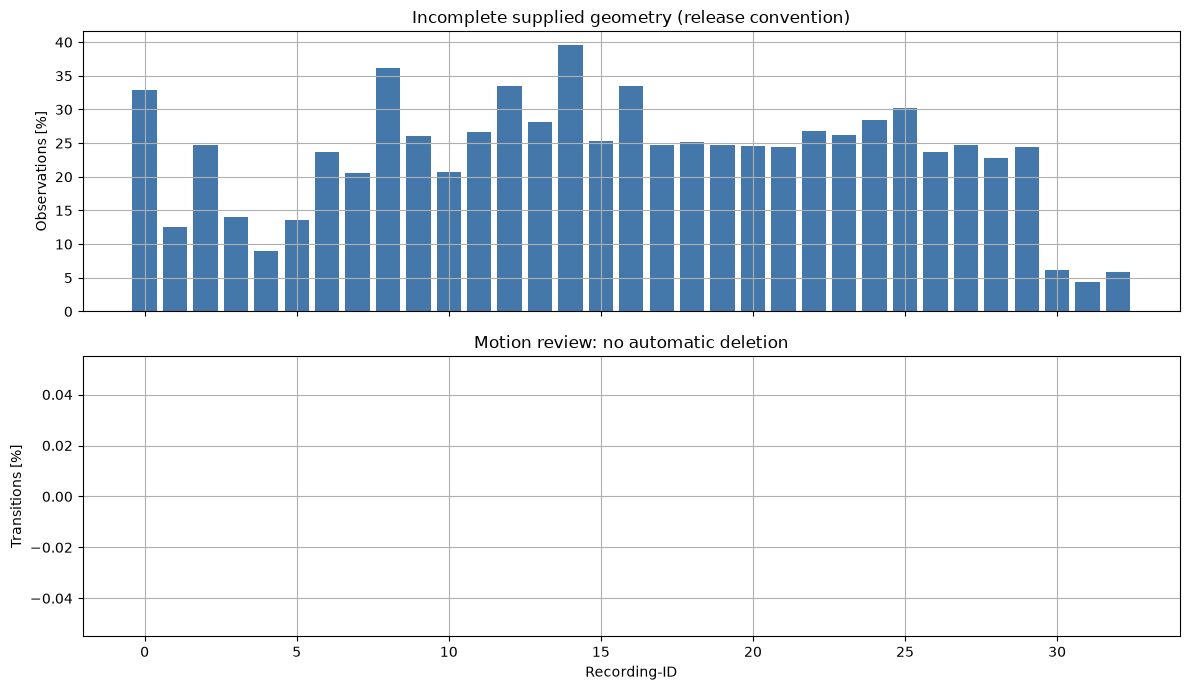

,recordingId,detections,zero_geometry_rows,eligible_motion_transitions,motion_review_flags,gap_events,missing_frames
0,0,205275,67565,204891,0,0,0
1,1,193248,24259,192863,0,0,0
2,2,247649,61364,247257,0,0,0
3,3,170495,23940,170191,0,0,0
4,4,98165,8847,97983,0,0,0
5,5,161731,21969,161419,0,0,0
6,6,204465,48463,204077,0,0,0
7,7,201296,41367,201084,0,0,0
8,8,260348,94037,259933,0,0,0
9,9,152101,39660,151865,0,0,0


Motion review rule: > 60 m/s; no rows removed.


In [133]:
# Geometry rates use observations; motion rates use eligible transitions.
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
geometry_rate = 100 * quality_report.zero_geometry_rows / quality_report.detections
motion_rate = 100 * quality_report.motion_review_flags / quality_report.eligible_motion_transitions.replace(0, np.nan)
axes[0].bar(quality_report.recordingId, geometry_rate, color='#4477AA')
axes[1].bar(quality_report.recordingId, motion_rate, color='#AA3377')
axes[0].set(title='Incomplete supplied geometry (release convention)', ylabel='Observations [%]')
axes[1].set(title='Motion review: no automatic deletion', ylabel='Transitions [%]', xlabel='Recording-ID')
plt.tight_layout()
plt.show()

# Show counts alongside rates and label the threshold as a review proposal.
display(quality_report[['recordingId', 'detections', 'zero_geometry_rows',
                        'eligible_motion_transitions', 'motion_review_flags', 'gap_events', 'missing_frames']])
print(f'Motion review rule: > {REVIEW_SPEED_LIMIT_M_S:g} m/s; no rows removed.')

**Interpretation → action:** zero geometry is a documented release convention, not automatically poor quality. Large movement is a review flag, not a deletion rule. Inspect class context and individual cases before deciding on any treatment.

`field_quality` contains cell counts, missing values, non-numeric values and infinities for every numeric track field, including release-reference fields that are not model inputs.

### 3.4 Class distribution by location

**Question / display / purpose:** the heatmaps compare absolute counts and class shares at each location, separately for tracks and observations. This reveals missing/rare classes and differences caused by longer tracks contributing more frame rows.

**Read:** rows are locations; columns are classes. Count colours use a logarithmic scale, but cell labels show actual counts. Percentage panels show shares within a location. These are complete counts, not EDA-sample estimates.

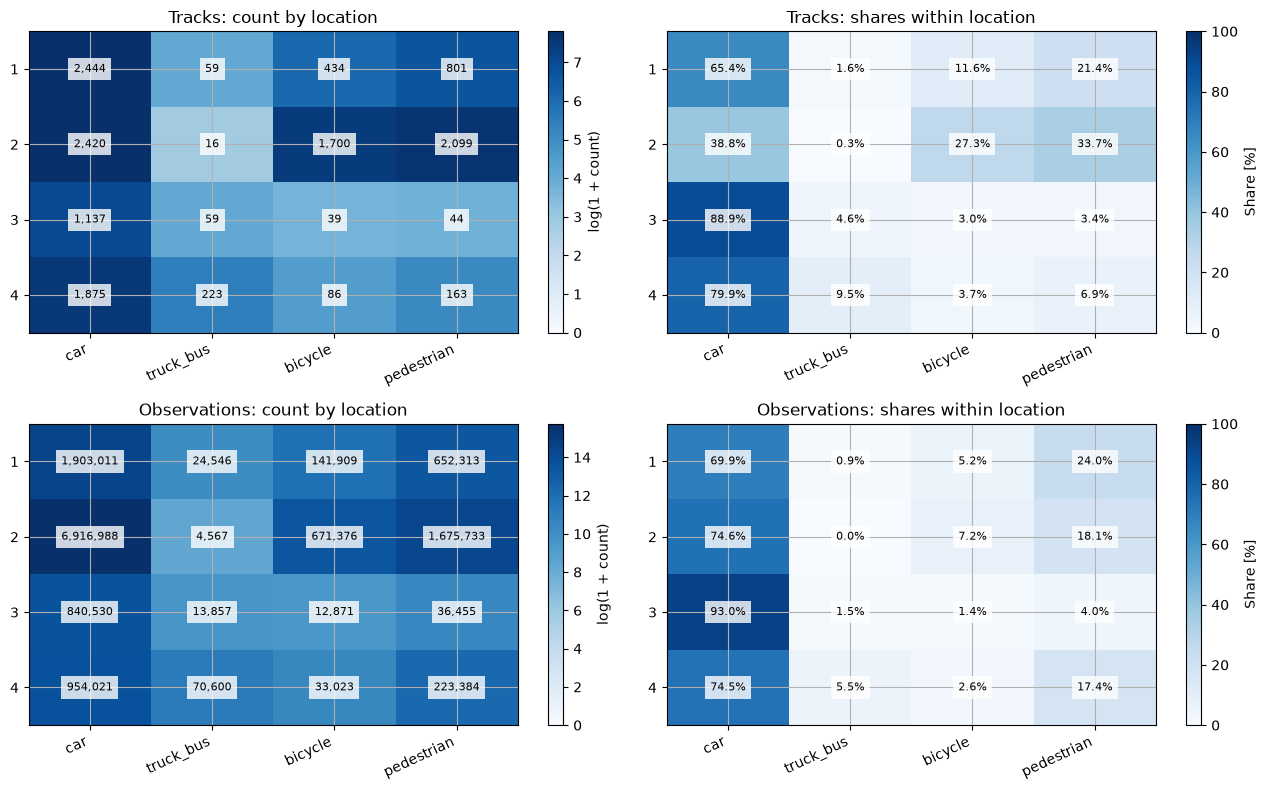

class,car,truck_bus,bicycle,pedestrian
locationId,,,,
1,2444,59,434,801
2,2420,16,1700,2099
3,1137,59,39,44
4,1875,223,86,163


class,car,truck_bus,bicycle,pedestrian
locationId,,,,
1,1903011,24546,141909,652313
2,6916988,4567,671376,1675733
3,840530,13857,12871,36455
4,954021,70600,33023,223384


,recordings,duration_s
locationId,,
1,11,11121.04
2,12,14553.64
3,3,3063.80
4,7,6610.76


In [134]:
# Attach location information without duplicating tracks.
meta_locations = meta_all.merge(inventory[['recordingId', 'locationId', 'frame_rate_hz']],
                                on='recordingId', validate='many_to_one')
class_tracks_location = pd.crosstab(meta_locations.locationId, meta_locations['class'])
class_tracks_location = class_tracks_location.reindex(columns=CLASS_ORDER, fill_value=0)
class_detections_location = meta_locations.pivot_table(
    index='locationId', columns='class', values='numFrames', aggfunc='sum', fill_value=0)
class_detections_location = class_detections_location.reindex(columns=CLASS_ORDER, fill_value=0)

# Convert each row to class shares; counts and shares answer different questions.
track_shares = class_tracks_location.div(class_tracks_location.sum(axis=1), axis=0) * 100
observation_shares = class_detections_location.div(class_detections_location.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
draw_heatmap(axes[0, 0], class_tracks_location, 'Tracks: count by location')
draw_heatmap(axes[0, 1], track_shares, 'Tracks: shares within location', percent=True)
draw_heatmap(axes[1, 0], class_detections_location, 'Observations: count by location')
draw_heatmap(axes[1, 1], observation_shares, 'Observations: shares within location', percent=True)
plt.tight_layout()
plt.show()
display(class_tracks_location)
display(class_detections_location)
display(inventory.groupby('locationId').agg(recordings=('recordingId', 'nunique'), duration_s=('duration_s', 'sum')))

**Interpretation → action:** differences between track and observation weighting are not automatically errors. Location-dependent class mixtures matter for later evaluation; check class support now and revisit split coverage during later preparation.

### 3.4.1 Speed and acceleration distributions by class

**Question / display / purpose:** The KDE plots compare speed and acceleration distributions across object classes (bicycle, car, pedestrian, truck_bus). This helps identify differences in movement behaviour and unusual values within individual classes.

**Read:** Each line represents one object class. The x-axis shows speed in km/h or acceleration in m/s². The y-axis shows probability density, not the number of observations. Each distribution is normalized, so peak heights depend on how concentrated the values are. For readability, a maximum of 4,000 observations per class is used.

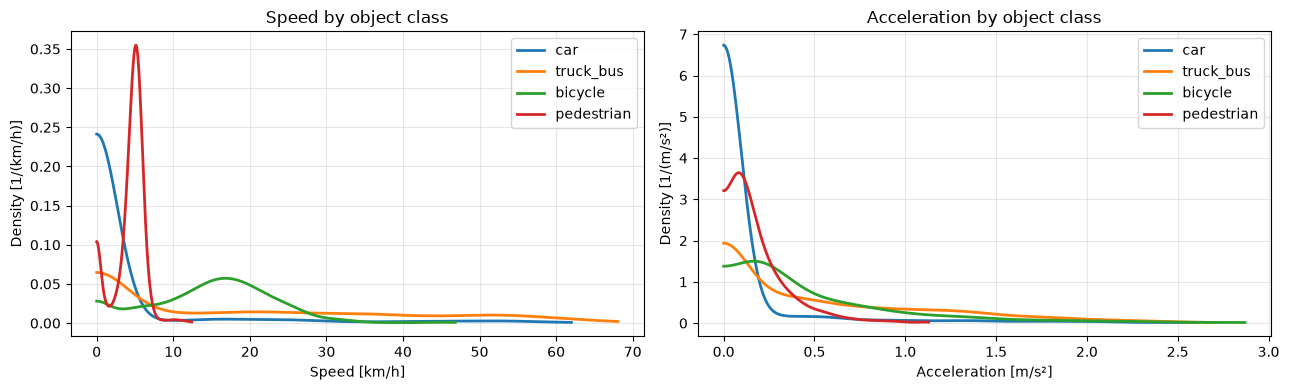

In [135]:
# Combine observations from all recordings.
motion_data = pd.concat(speed_data, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for cls in CLASS_ORDER:
    group = motion_data[motion_data["class_name"] == cls]
    if group.empty:
        continue
    plot_density(axes[0], group["speed_kmh"], cls, 0.5)
    plot_density(axes[1], group["acceleration"], cls, 0.05)
axes[0].set(
    title="Speed by object class",
    xlabel="Speed [km/h]",
    ylabel="Density [1/(km/h)]"
)
axes[1].set(
    title="Acceleration by object class",
    xlabel="Acceleration [m/s²]",
    ylabel="Density [1/(m/s²)]"
)
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretation → action:** Differences between object classes are expected due to their different movement characteristics. Unusually high speeds or acceleration values may indicate incorrect assignments or tracking errors. Investigate extreme values within each class using the corresponding tracks and trajectories.

### 3.5 Track counts and duration

**Question / display / purpose:** show class counts, a duration boxplot and a duration ECDF. The ECDF shows the fraction of tracks at or below each duration, including extremes hidden by the boxplot.

**Unit:** one track counts once. Duration means elapsed time between the first and last observation: `(last_frame - first_frame) / frameRate`, not sample count divided by frame rate.

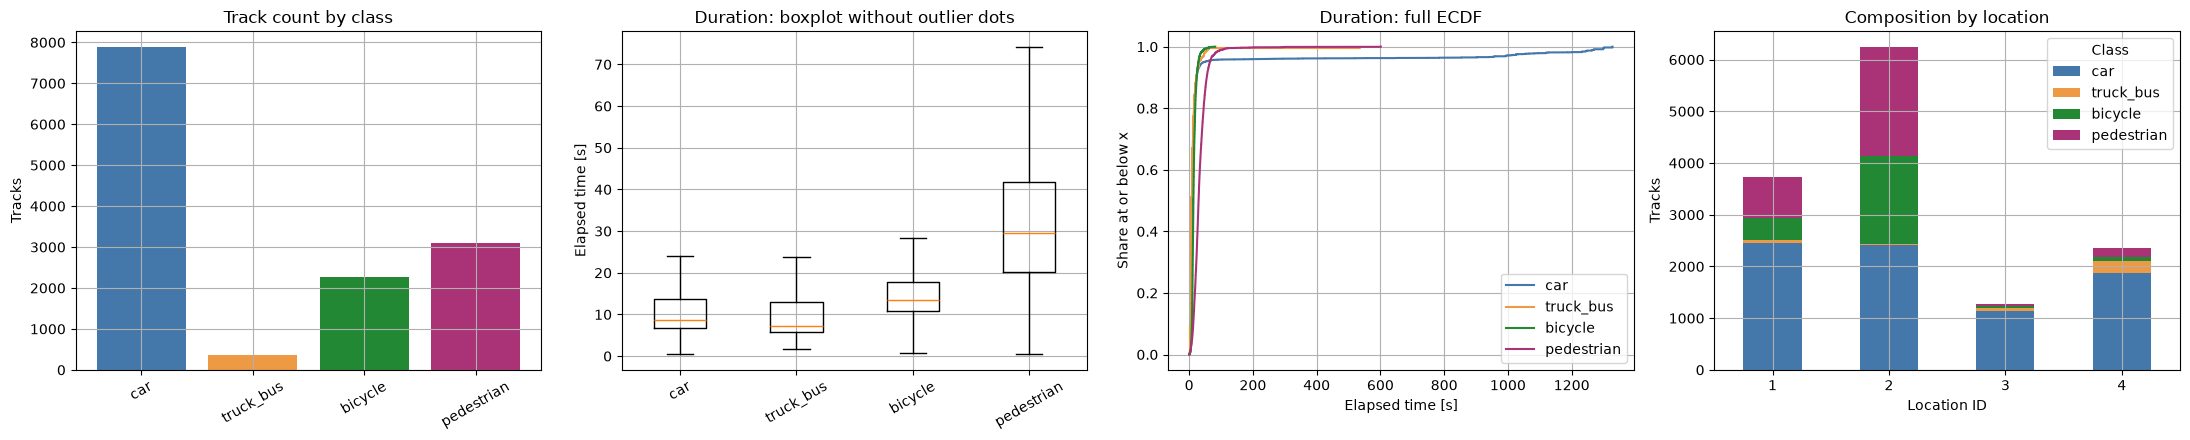

,count,mean,std,min,25%,50%,75%,95%,99%,max
class,,,,,,,,,,
car,7876.0,53.868329,214.946587,0.40,6.64,8.76,13.60,45.520,1269.3600,1328.24
truck_bus,357.0,12.684930,29.821070,1.76,5.76,7.32,13.08,31.256,57.6816,536.80
bicycle,2259.0,15.173440,7.649764,0.68,10.72,13.36,17.82,28.884,44.8568,81.92
pedestrian,3107.0,33.276833,23.693225,0.44,20.28,29.52,41.88,64.776,100.2968,601.56


meta_all columns: ['recordingId', 'trackId', 'initialFrame', 'finalFrame', 'numFrames', 'width', 'length', 'class']
track_diagnostics columns: ['gap_events', 'missing_frames', 'longest_gap', 'coverage', 'duplicate_frames', 'recordingId', 'locationId', 'trackId', 'class', 'observed_frames', 'first_frame', 'last_frame', 'elapsed_s', 'extent_m', 'straightness', 'turn_deg', 'turning_deg_per_m']


In [136]:
# Retain class counts and add the complete duration ECDF.
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
track_counts = meta_all['class'].value_counts().reindex(CLASS_ORDER, fill_value=0)
axes[0].bar(CLASS_ORDER, track_counts, color=[CLASS_COLORS[name] for name in CLASS_ORDER])
axes[0].set(title='Track count by class', ylabel='Tracks')

# Hide outlier dots only in the boxplot; retain all values in the ECDF and table.
durations = [track_diagnostics.loc[track_diagnostics['class'] == name, 'elapsed_s'].to_numpy() for name in CLASS_ORDER]
axes[1].boxplot(durations, tick_labels=CLASS_ORDER, showfliers=False)
axes[1].set(title='Duration: boxplot without outlier dots', ylabel='Elapsed time [s]')
for class_name, values in zip(CLASS_ORDER, durations):
    draw_ecdf(axes[2], values, label=class_name, color=CLASS_COLORS[class_name])
axes[2].set(title='Duration: full ECDF', xlabel='Elapsed time [s]', ylabel='Share at or below x')
axes[2].legend()
for ax in axes[:2]:
    ax.tick_params(axis='x', labelrotation=30)

class_by_location = (track_diagnostics.groupby(["locationId", "class"]).size().unstack(fill_value=0).reindex(columns=CLASS_ORDER, fill_value=0).sort_index()
)
class_by_location.plot.bar(stacked=True,ax=axes[3],rot=0,color=[CLASS_COLORS[name] for name in CLASS_ORDER],)
axes[3].set(
    title="Composition by location",
    xlabel="Location ID",
    ylabel="Tracks",
)
axes[3].legend(title="Class")

plt.tight_layout()
plt.show()

# Print actual quantiles instead of pre-written numerical claims.
display(track_diagnostics.groupby('class').elapsed_s.describe(percentiles=[.25, .5, .75, .95, .99]).reindex(CLASS_ORDER))

print("meta_all columns:", meta_all.columns.tolist())
print("track_diagnostics columns:", track_diagnostics.columns.tolist())


**Interpretation → action:** duration depends on speed, waiting, field of view and recording boundaries. A long observed duration does not necessarily mean a long travelled distance. Do not remove or trim tracks simply because they last longer.

### 3.6 Geometry availability by class

Bicycles and Pedestrians do not have geometry data available. We decided to generate geometry data from a normal distribution for both bicycles and pedestrians

#### 3.6.1 Width, length and their relationship
TODO: someone had a better plot for that. Replace this plot please.

**Question / display / purpose:** histograms show the supplied dimensions; a scatter plot compares width and length by class. Each track counts once, so long tracks do not dominate these plots. Only positive supplied geometry is shown; zero shares are reported above.

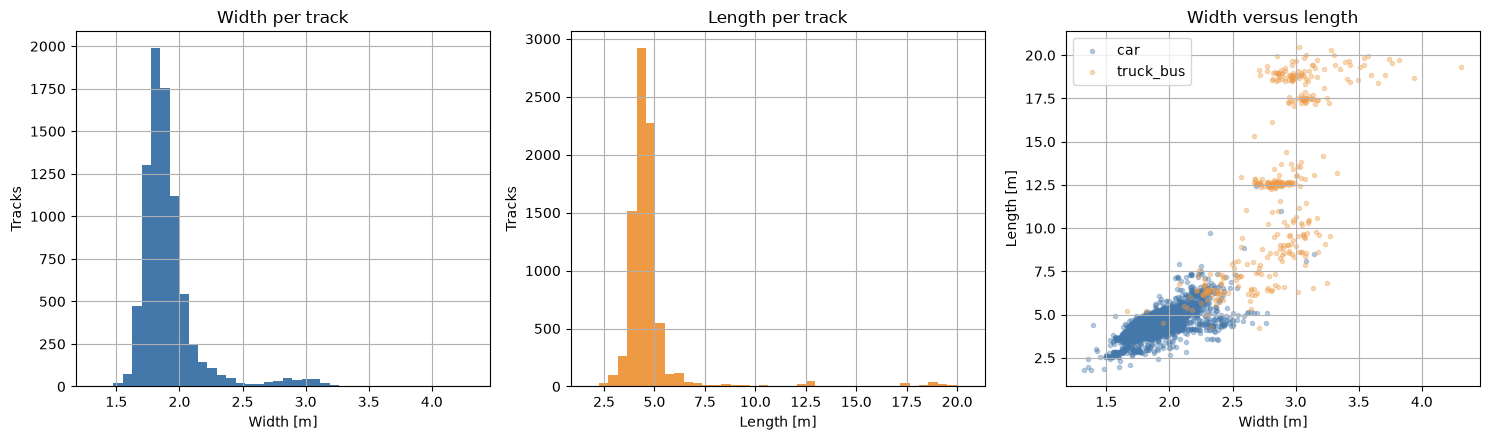

width                                                           \
            count      mean       std      min       25%      50%      75%   
class                                                                        
car        7876.0  1.871292  0.144732  1.32620  1.778348  1.85158  1.94038   
truck_bus   357.0  2.858087  0.334680  1.66714  2.707740  2.88885  3.04327   

                    length                                                    \
               max   count       mean       std      min      25%        50%   
class                                                                          
car        3.14454  7876.0   4.460809  0.578718  1.77949  4.12549   4.453845   
truck_bus  4.31195   357.0  12.521038  4.918520  4.20915  7.94176  12.539790   

                               
                75%       max  
class                          
car         4.76621  12.41258  
truck_bus  17.67040  20.44562

In [137]:
# Plot positive supplied geometry only; zero shares are reported above.
with_geometry = meta_all[(meta_all.width > 0) & (meta_all.length > 0)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].hist(with_geometry.width, bins=40, color='#4477AA')
axes[1].hist(with_geometry.length, bins=40, color='#EE9944')
axes[0].set(title='Width per track', xlabel='Width [m]', ylabel='Tracks')
axes[1].set(title='Length per track', xlabel='Length [m]', ylabel='Tracks')
for class_name in CLASS_ORDER:
    group = with_geometry[with_geometry['class'] == class_name]
    if len(group):
        axes[2].scatter(group.width, group.length, s=9, alpha=.35, color=CLASS_COLORS[class_name], label=class_name)
axes[2].set(title='Width versus length', xlabel='Width [m]', ylabel='Length [m]')
if len(with_geometry):
    axes[2].legend()
plt.tight_layout()
plt.show()
display(with_geometry.groupby('class')[['width', 'length']].describe())

**Interpretation → action:** these plots describe released metadata, not future classification accuracy. Classes without supplied geometry are absent from these distributions, not absent from the dataset.

### 3.7 Heading without nearly stationary car tracks

**Question / display / purpose:** repeat the heading plot below the original, excluding observations from long-term stationary car candidates. Blue is the filtered sample; the grey outline is the original sample on the same bins and per-location count scale.

**Rule:** the complete released track must be a `car`, span at least **60 seconds**, contain no internal frame gaps and fit inside a spatial bounding rectangle with a diagonal no larger than **1 metre**. The thresholds below are analysis choices, not a validated parking detector. Whole-track summaries are reused from the first data pass; CSVs do not need to be read again.

**Limit:** a car waiting for its entire observed lifetime can also be flagged. A parked car observed only briefly can remain. Short stops in an otherwise moving track are not removed; other classes, including `truck_bus`, remain unchanged.

**Scope:** filter only this additional view, using the same EDA sample without resampling. Original plots, raw data and model/export inputs stay unchanged.

In [138]:
# Set visible analysis thresholds; these are not validated parking labels.
PARK_MIN_OBSERVED_SECONDS = 60.0
PARK_MAX_EXTENT_M = 1.0

# Reject invalid thresholds rather than silently changing what the filter means.
assert np.isfinite(PARK_MIN_OBSERVED_SECONDS) and PARK_MIN_OBSERVED_SECONDS > 0
assert np.isfinite(PARK_MAX_EXTENT_M) and PARK_MAX_EXTENT_M >= 0

# Reuse whole-track summaries from the first pass instead of reading all CSVs again.
parking_track_summary = track_diagnostics.copy()
parking_track_summary['park_candidate'] = (
    (parking_track_summary['class'] == 'car')
    & (parking_track_summary.elapsed_s >= PARK_MIN_OBSERVED_SECONDS)
    & (parking_track_summary.extent_m <= PARK_MAX_EXTENT_M)
    & (parking_track_summary.gap_events == 0)
)

# Filter a separate copy of the SAME EDA sample; keep all other data unchanged.
parking_flags = parking_track_summary[KEYS + ['park_candidate']]
heading_comparison = eda.merge(parking_flags, on=KEYS, how='left', validate='many_to_one')
assert len(heading_comparison) == len(eda)
assert heading_comparison.park_candidate.notna().all(), 'Missing whole-track summary.'
eda_heading_filtered = heading_comparison[~heading_comparison.park_candidate].copy()

**Read the comparison:** bar angle means orientation and bar length means frame-observation count. Where blue falls below grey, observations of candidate tracks were excluded. This is not a verified count of parked cars. The table separates excluded sample rows from the number of complete candidate tracks.

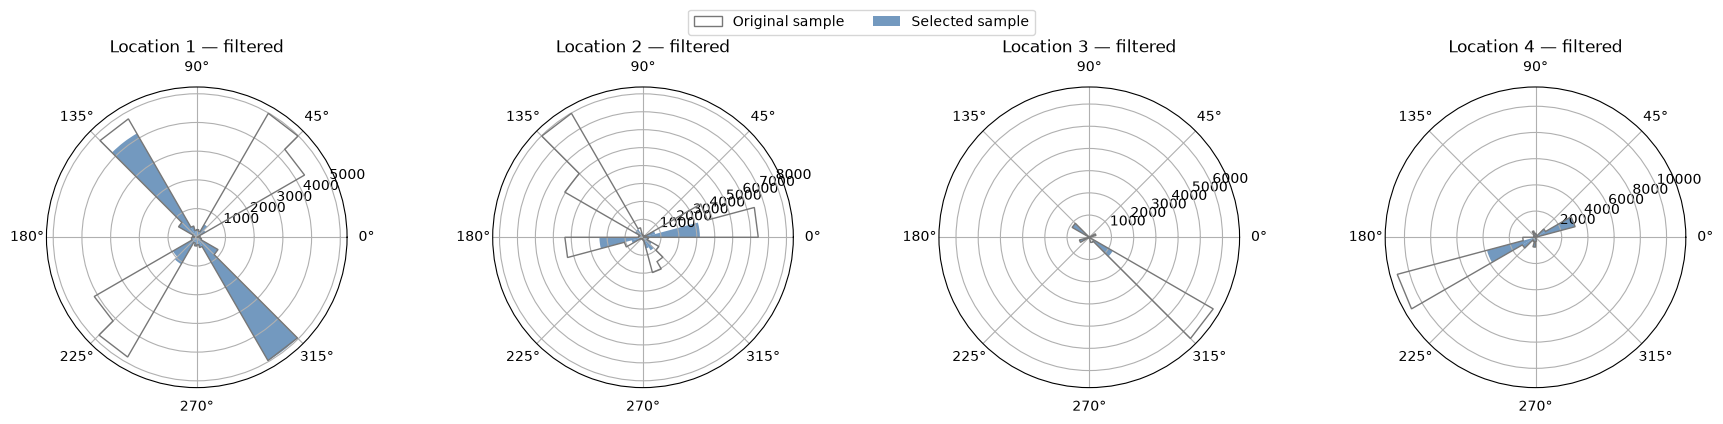

,locationId,original_sample_rows,excluded_sample_rows,retained_sample_rows,circular_mean_deg,resultant_length,all_tracks,parked_candidate_tracks
0,1,33000,15942,17058,257.832702,0.091144,3738,57
1,2,36000,23434,12566,335.023865,0.106491,6235,222
2,3,9000,5956,3044,236.328234,0.104796,1279,25
3,4,21000,8069,12931,208.129994,0.149125,2347,21


Only this comparison view is filtered; the original and model/export data are unchanged.


In [139]:
# Reuse the original sample and bins; only the candidate-track observations are excluded.
locations = sorted(eda.locationId.unique())
fig, axes = plt.subplots(1, len(locations), figsize=(4.5 * len(locations), 4),
                         subplot_kw={'projection': 'polar'}, squeeze=False)
filtered_heading_rows = []
for ax, location_id in zip(axes[0], locations):
    reference = eda.loc[eda.locationId == location_id, 'heading']
    headings = eda_heading_filtered.loc[eda_heading_filtered.locationId == location_id, 'heading']
    draw_heading(ax, headings, f'Location {int(location_id)} — filtered', reference=reference)
    stats = circular_summary(headings)
    filtered_heading_rows.append({'locationId': location_id, 'original_sample_rows': len(reference),
        'excluded_sample_rows': len(reference) - len(headings), 'retained_sample_rows': len(headings), **stats})
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc='upper center', ncol=2, bbox_to_anchor=(.5, 1.06))
plt.tight_layout()
plt.show()

# Keep candidate-track counts separate from excluded sample-row counts.
candidate_counts = parking_track_summary.groupby('locationId').agg(
    all_tracks=('trackId', 'size'), parked_candidate_tracks=('park_candidate', 'sum'))
heading_filter_report = pd.DataFrame(filtered_heading_rows)
heading_filter_report = heading_filter_report.merge(candidate_counts, on='locationId', validate='one_to_one')
display(heading_filter_report)
print('Only this comparison view is filtered; the original and model/export data are unchanged.')

**Interpretation → action:** a changed distribution shows the influence of long-term stationary car candidates on this frame-weighted sample. It does not prove parking or that every remaining object is moving. Confirmed parking would require additional evidence such as checked parking areas and visual review. No model-input rows are removed.

### 3.8 Active motor vehicles by time of day

**Question / display / purpose:** how many motor vehicles are in the recorded area at the same time, and does this change over the afternoon? The location with the most recordings is used, so each time of day is covered by several recordings. The top rows show each recording day as a stacked area (30-second means); long-term stationary cars (rule from 3.7) are a separate grey layer, because they are parked, not traffic.

**Clock time is approximate:** `recordingMeta.startTime` contains only the start hour. Recordings with the same weekday and start hour are assumed to have run back to back in `recordingId` order; the code stops if that pushes a start past its hour. Weekday labels are normalised (`tuesdays` → `Tuesday`). This describes simultaneous occupancy, not vehicles per hour across a counting line.

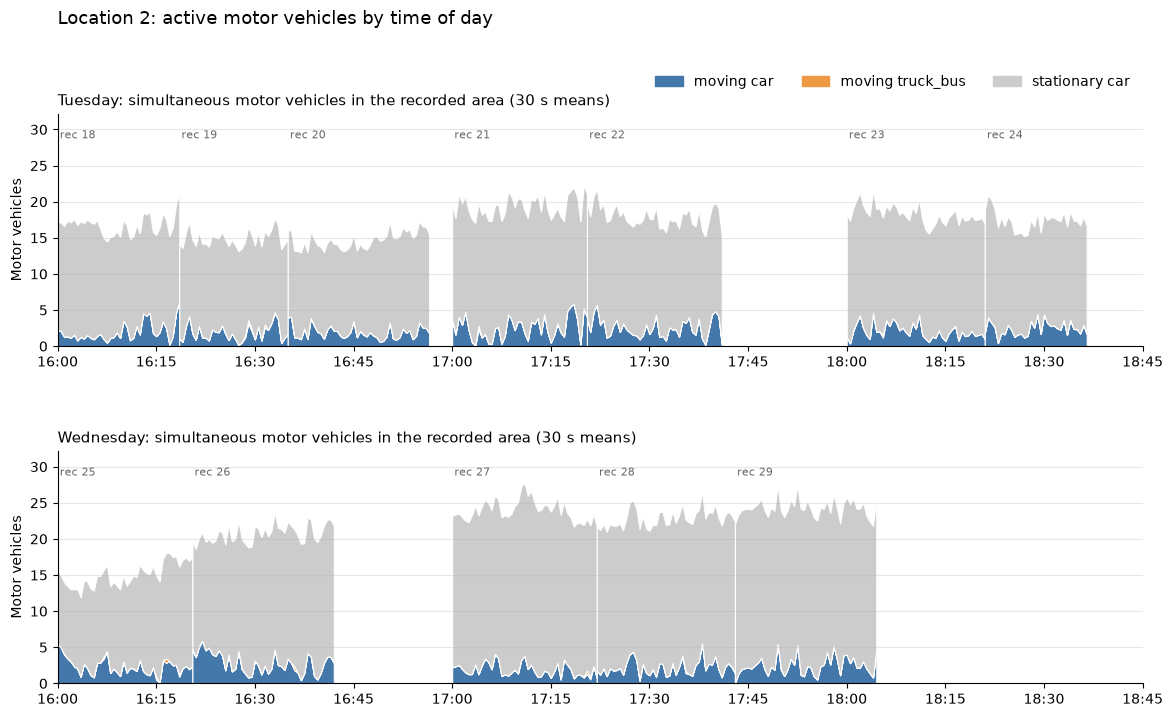

0 seconds without any CSV entry; not treated as empty.


In [140]:
# Use the location with the most recordings, so time of day is covered by several recordings.
from matplotlib.ticker import FuncFormatter, MultipleLocator
MOTOR_CLASSES = ['car', 'truck_bus']
# Long-term stationary cars (3.7 rule) are parked, not traffic; show them separately.
OCCUPANCY_LAYERS = MOTOR_CLASSES + ['stationary car']
LAYER_COLORS = {**CLASS_COLORS, 'stationary car': '#CCCCCC'}
WINDOW_S = 15 * 60
recording_locations = {rid: int(read_metadata(rid)[1].locationId) for rid in RECORDINGS}
occupancy_location = pd.Series(recording_locations).value_counts().idxmax()
occupancy_recordings = [rid for rid, loc in recording_locations.items() if loc == occupancy_location]

# recordingMeta gives only the start hour; assume recordings within one weekday/hour ran back to back.
starts = []
for rid in occupancy_recordings:
    recording = read_metadata(rid)[1]
    starts.append({'recordingId': rid, 'weekday': str(recording.weekday).rstrip('s').capitalize(),
                   'start_hour': int(recording.startTime), 'duration_s': float(recording.duration)})
starts = pd.DataFrame(starts).sort_values('recordingId')
starts['offset_s'] = starts.groupby(['weekday', 'start_hour']).duration_s.cumsum() - starts.duration_s
assert (starts.offset_s < 3600).all(), 'Back-to-back assumption pushes a recording past its start hour.'
starts['clock_start_s'] = starts.start_hour * 3600 + starts.offset_s

# Count motor vehicles per frame; frame indices without any CSV entry stay NaN, not zero.
occupancy_parts = []
for row in starts.itertuples():
    frame_rows, meta, recording = read_recording(row.recordingId, usecols=KEYS + ['frame'])
    frame_rows = frame_rows.merge(meta[KEYS + ['class']], on=KEYS).merge(
        parking_track_summary[KEYS + ['park_candidate']], on=KEYS, how='left', validate='many_to_one')
    frame_rows['layer'] = frame_rows['class'].where(~frame_rows.park_candidate.fillna(False).astype(bool), 'stationary car')
    counts = pd.crosstab(frame_rows.frame, frame_rows.layer).reindex(columns=OCCUPANCY_LAYERS, fill_value=0)
    counts = counts.reindex(range(int(frame_rows.frame.min()), int(frame_rows.frame.max()) + 1))
    counts['clock_s'] = row.clock_start_s + counts.index / float(recording.frameRate)
    counts['second'] = np.floor(counts.clock_s)
    per_second = counts.groupby('second')[OCCUPANCY_LAYERS].mean().reset_index()
    per_second['recordingId'], per_second['weekday'] = row.recordingId, row.weekday
    occupancy_parts.append(per_second)
occupancy = pd.concat(occupancy_parts, ignore_index=True)
# 'total' counts moving motor vehicles only; stationary cars stay in their own column.
occupancy['total'] = occupancy[MOTOR_CLASSES].sum(axis=1, min_count=1)
occupancy['window'] = (occupancy.second // WINDOW_S * WINDOW_S).astype(int)

clock = FuncFormatter(lambda s, _: f'{int(s // 3600):02d}:{int(s % 3600 // 60):02d}')
days = sorted(occupancy.weekday.unique(), key=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'].index)
windows = sorted(occupancy.window.unique())
x_min, x_max = windows[0], windows[-1] + WINDOW_S
y_max = occupancy[OCCUPANCY_LAYERS].sum(axis=1).quantile(.995) * 1.15

fig, day_axes = plt.subplots(len(days), 1, figsize=(14, 3.2 * len(days) + 1), squeeze=False, gridspec_kw={'hspace': .45})
day_axes = day_axes[:, 0]

# One row per day: 30-second means, stacked by class; gaps between recordings stay empty.
for ax, day in zip(day_axes, days):
    for rid, part in occupancy[occupancy.weekday == day].groupby('recordingId'):
        smooth = part.groupby(part.second // 30 * 30)[OCCUPANCY_LAYERS].mean()
        ax.stackplot(smooth.index, *[smooth[name] for name in OCCUPANCY_LAYERS],
                     colors=[LAYER_COLORS[name] for name in OCCUPANCY_LAYERS], edgecolor='white', linewidth=.8)
        ax.text(smooth.index[0] + 20, y_max * .93, f'rec {rid:02d}', fontsize=8, color='#666666', va='top')
    ax.set(xlim=(x_min, x_max), ylim=(0, y_max), ylabel='Motor vehicles')
    ax.set_title(f'{day}: simultaneous motor vehicles in the recorded area (30 s means)', loc='left', fontsize=11)
for ax in day_axes:
    ax.xaxis.set_major_locator(MultipleLocator(WINDOW_S))
    ax.xaxis.set_major_formatter(clock)
    ax.grid(axis='x', visible=False)
    ax.grid(axis='y', alpha=.3)
    ax.spines[['top', 'right']].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=LAYER_COLORS[name]) for name in OCCUPANCY_LAYERS]
day_axes[0].legend(handles, ['moving car', 'moving truck_bus', 'stationary car'], loc='upper right', frameon=False, ncol=3, bbox_to_anchor=(1, 1.22))

fig.suptitle(f'Location {occupancy_location}: active motor vehicles by time of day', x=.125, ha='left', fontsize=13, y=1.02)
plt.show()

print(f'{int(occupancy.total.isna().sum())} seconds without any CSV entry; not treated as empty.')

**Interpretation → action:** most simultaneously present cars are stationary (parked) candidates, so raw object counts mainly reflect parking occupancy. Moving motor vehicles stay at roughly one to five at a time throughout the afternoon, without a clear time-of-day trend; trucks/buses are almost absent at this location. Many simultaneous objects give more possible association candidates, but do not alone prove difficult tracking; the later ambiguity diagnostic tests this more directly.

### 3.9 Track continuity: are frames missing inside a track?

**Purpose:** count, for every track in every recording, how many frames are missing between its first and last observation.

In [141]:
# Check every track over all recordings for frames missing between its first and last observation.
tracks_with_gaps = int((track_diagnostics.missing_frames > 0).sum())
if tracks_with_gaps == 0:
    print(f"No missing frames: all {len(track_diagnostics):,} tracks in {track_diagnostics.recordingId.nunique()} recordings are complete.")
else:
    print(f"{tracks_with_gaps:,} of {len(track_diagnostics):,} tracks have missing frames.")

No missing frames: all 13,599 tracks in 33 recordings are complete.


**Conclusion:** no track has internal frame gaps; since the dataset creators already bridged gaps, this does not prove the detector never missed an object.

### 3.10 Movement distributions:

**Question / display / purpose:** the left ECDF shows distance between adjacent frames. The right shows distance divided by the actual elapsed time, so it can also handle a transition across a gap correctly.

Each transition contributes a value. Curve height is the share of values at or below the x-axis value. Larger steps can make simple distance matching harder. GT links are used only to calculate the diagnostic, not as input features.

**Scope:** at most `MOTION_SAMPLE_PER_RECORDING` reproducibly sampled transitions per recording. This is recording-balanced, not automatically representative of a random transition in the whole release.

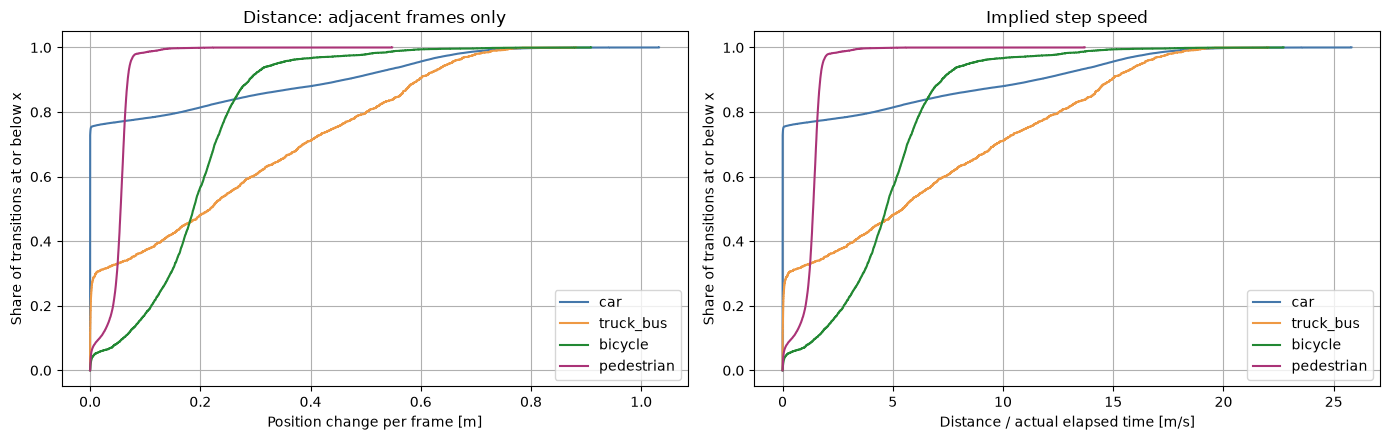

count      mean       std       min       25%  \
locationId class                                                         
1          bicycle      1803.0  4.889234  2.312259  0.001601  3.802796   
           car         23181.0  1.873419  3.858845  0.000000  0.000000   
           pedestrian   7730.0  1.352666  0.489153  0.000559  1.241276   
           truck_bus     286.0  3.788655  4.440742  0.000000  0.000000   
2          bicycle      2617.0  4.185490  2.075854  0.003250  2.777517   
           car         26861.0  0.553735  1.777828  0.000000  0.000000   
           pedestrian   6496.0  1.316658  0.498462  0.001061  1.150528   
           truck_bus      26.0  3.925487  2.258142  0.878599  1.949826   
3          bicycle       105.0  6.455892  3.949009  0.015572  3.603876   
           car          8405.0  2.380710  4.718662  0.000000  0.000000   
           pedestrian    351.0  1.309261  0.434859  0.024251  1.142073   
           truck_bus     139.0  5.958462  5.100141  0.000000  0.625133   
4          bicycle       489.0  6.540017  4.256482  0.007957  3.967462   
           car         15982.0  5.983962  7.224265  0.000000  0.000000   
           pedestrian   3385.0  1.073277  0.745332  0.000000  0.401156   
           truck_bus    1144.0  6.964326  6.048896  0.000000  0.184325   

                            50%        75%        95%        99%        max  
locationId class                                                             
1          bicycle     5.003350   6.083126   8.242542  12.425750  14.692845  
           car         0.000000   0.100761  11.698871  14.036416  23.774147  
           pedestrian  1.424902   1.563813   1.790873   2.549003  13.705193  
           truck_bus   0.099731   7.713248  11.574295  13.501705  15.610848  
2          bicycle     4.361890   5.584996   7.447659   8.763636  11.332418  
           car         0.000000   0.000000   5.402677   8.375830  12.816200  
           pedestrian  1.371040   1.556417   1.843896   3.023540   6.293948  
           truck_bus   3.104673   6.089526   7.153191   8.294124   8.641686  
3          bicycle     5.165254   8.874535  13.557150  13.833028  14.021755  
           car         0.000000   0.032558  13.267710  15.103161  20.956294  
           pedestrian  1.353400   1.581999   1.752283   1.995353   3.963658  
           truck_bus   4.888518  11.637153  13.741161  14.279104  15.374711  
4          bicycle     5.373969   6.928891  15.513732  18.759050  22.724732  
           car         0.000000  14.134477  17.691122  19.878547  25.808498  
           pedestrian  1.284522   1.528440   1.883946   3.204129  12.461174  
           truck_bus   6.169957  12.617628  16.834047  18.771990  22.035264

No additional smoothing, clipping or removal of unusual movement.


In [142]:
# Compare step distances only across adjacent frames; speed uses real time gaps.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for class_name in CLASS_ORDER:
    group = motion_eda[motion_eda['class'] == class_name]
    adjacent_steps = group.loc[group.delta_frame == 1, 'distance_m']
    draw_ecdf(axes[0], adjacent_steps, label=class_name, color=CLASS_COLORS[class_name])
    draw_ecdf(axes[1], group.speed_m_s, label=class_name, color=CLASS_COLORS[class_name])
axes[0].set(title='Distance: adjacent frames only', xlabel='Position change per frame [m]', ylabel='Share of transitions at or below x')
axes[1].set(title='Implied step speed', xlabel='Distance / actual elapsed time [m/s]', ylabel='Share of transitions at or below x')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

# Show quantiles and sample size by class/location; do not fit arbitrary cutoffs.
display(motion_eda.groupby(['locationId', 'class']).speed_m_s.describe(percentiles=[.25, .5, .75, .95, .99]))
print('No additional smoothing, clipping or removal of unusual movement.')

**Interpretation → action:** these values come from already smoothed inD positions. Stops and turns can be valid. No smoothing, clipping or automatic removal is applied. Any later model thresholds should be justified using training data rather than fitted on the test location.

#### 3.10.1 Speed and trajectory shape by class

**Question / display / purpose:** How do observed speeds and trajectory shapes
differ between road-user classes? The plots show sampled observation speeds,
overall net turn, straightness and accumulated direction change.

**Unit:** Speed uses a sample of frame observations, so longer tracks can
contribute more observations. The other plots use one eligible value per track.

**Read:** Boxplot lines show medians and boxes show the middle half of values.
Speed outlier dots are hidden. Net turn compares the first and last reliable
movement directions; its histogram shows probability density, not track counts.
Straightness compares displacement with path length. Direction change per
metre describes how much the movement direction changes along eligible bouts.


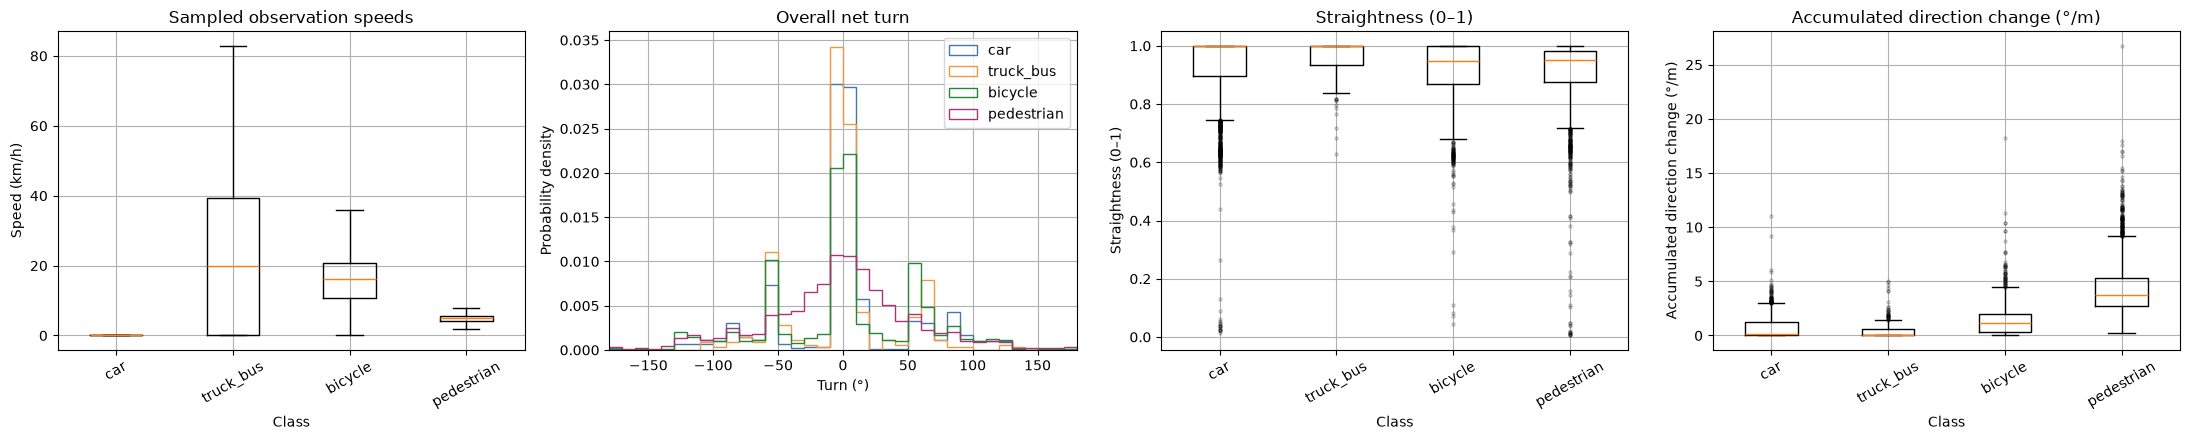

In [143]:
speeds = pd.concat(speed_data, ignore_index=True)
sample = speeds.sample(min(200_000, len(speeds)), random_state=17)

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))

# 1. Sampled observation speeds
groups = [sample.loc[sample['class_name'] == c, 'speed_kmh'].dropna() for c in CLASS_ORDER]
axes[0].boxplot(groups, tick_labels=CLASS_ORDER, showfliers=False)
axes[0].set(title='Sampled observation speeds', xlabel='Class', ylabel='Speed (km/h)')

# 2. Overall net turn
for c in CLASS_ORDER:
    values = track_diagnostics.loc[track_diagnostics['class'] == c, 'turn_deg'].dropna()
    if not values.empty:
        axes[1].hist(values, bins=np.linspace(-180, 180, 37), histtype='step',
                     density=True, color=CLASS_COLORS[c], label=c)

axes[1].set(title='Overall net turn', xlabel='Turn (°)',
            ylabel='Probability density', xlim=(-180, 180))
axes[1].legend()

# 3–4. Straightness and direction change
features = [
    ('straightness', 'Straightness (0–1)'),
    ('turning_deg_per_m', 'Accumulated direction change (°/m)')
]
for ax, (column, title) in zip(axes[2:], features):
    groups = [track_diagnostics.loc[track_diagnostics['class'] == c, column].dropna() for c in CLASS_ORDER]
    ax.boxplot(groups, tick_labels=CLASS_ORDER, showfliers=True,
               flierprops={'markersize': 2, 'alpha': 0.25})
    ax.set(title=title, xlabel='Class', ylabel=title)

for ax in (axes[0], axes[2], axes[3]):
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Interpretation → action:** Compare the distributions by class, while
remembering that their denominators differ: speed is observation-weighted,
whereas the shape measures are track-level and subject to eligibility rules.

A net turn near zero does not necessarily mean a straight trajectory: turns
along the way can cancel. Straightness and accumulated direction change provide
additional context. Tracks without enough reliable movement, and tracks with
gaps or invalid values where required, may be absent from the shape plots.

Differences may reflect road-user behaviour, intersection layout and the
recorded field of view. They do not by themselves indicate tracking errors or
justify removing observations.


### 3.11 Association ambiguity: could another candidate look plausible?

**Question / display / purpose:** compare distance from an observation in frame `t` to its true continuation and to the nearest wrong candidate in `t+1`. The margin is `d_false - d_true`: negative means a wrong candidate is closer.

This is a diagnostic for the local “choose the nearest object” rule, **not a calibrated confidence/probability or an overall tracking score**. A positive margin does not guarantee a globally correct assignment.

**Scope:** at most `AMBIGUITY_MAX_FRAME_PAIRS` time-spread adjacent-frame pairs from the detail recording, with all candidates in each selected frame and no GT-class restriction. Track endings, gaps, ties and frames without a distractor are reported separately.

In [144]:
# Limit selected adjacent-frame pairs, not the candidate count within each pair.
frame_indices = clean.groupby('frame').indices
all_frames = sorted(frame_indices)
possible_pairs = []
for frame in all_frames:
    if frame + 1 in frame_indices:
        possible_pairs.append(frame)
possible_pairs = np.array(possible_pairs, dtype=int)
number_to_use = min(len(possible_pairs), AMBIGUITY_MAX_FRAME_PAIRS)
chosen_positions = np.array([], dtype=int)
if number_to_use > 0:
    chosen_positions = np.linspace(0, len(possible_pairs) - 1, number_to_use, dtype=int)
chosen_frames = possible_pairs[chosen_positions]
class_lookup = active_meta.set_index('trackId')['class']
last_frame_lookup = active_meta.set_index('trackId').finalFrame
ambiguity_rows = []
for frame in chosen_frames:
    current = clean.iloc[frame_indices[frame]]
    following = clean.iloc[frame_indices[frame + 1]]
    rows = association_distances(current[['xCenter', 'yCenter']].to_numpy(), current.trackId.to_numpy(),
                                 following[['xCenter', 'yCenter']].to_numpy(), following.trackId.to_numpy())
    for row in rows:
        row['frame'] = int(frame)
        row['class'] = class_lookup.loc[row['trackId']]
        if row['status'] == 'no_next_observation':
            if last_frame_lookup.loc[row['trackId']] == frame:
                row['status'] = 'track_end'
            else:
                row['status'] = 'gap_to_next_observation'
    ambiguity_rows.extend(rows)

# Retain fixed columns for empty results so that case remains understandable.
ambiguity = pd.DataFrame(ambiguity_rows).reindex(columns=['frame', 'trackId', 'class', 'status', 'd_true_m', 'd_false_m', 'margin_m'])
assessable = ambiguity[ambiguity.status == 'eligible'].copy()
TIE_TOLERANCE_M = 1e-9
if len(assessable):
    assessable['closer_wrong_candidate'] = assessable.margin_m < -TIE_TOLERANCE_M
    assessable['tie'] = np.isclose(assessable.margin_m, 0, atol=TIE_TOLERANCE_M, rtol=0)

**Plot — local association ambiguity:** compare true and nearest-wrong distances on the left and their difference on the right. Zero margin is a tie, not a confidence threshold; only assessed competing cases enter these curves.

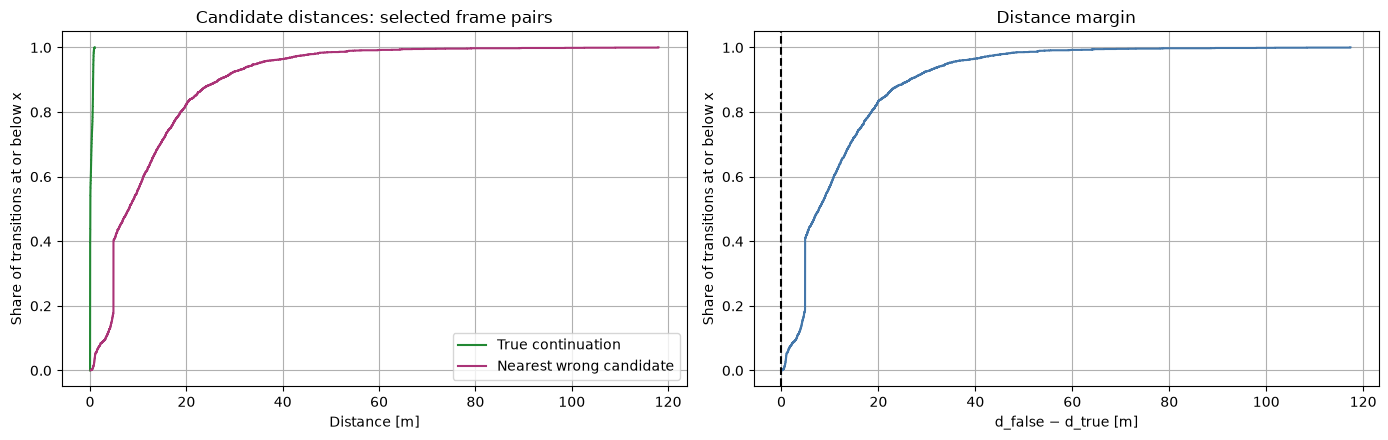

Recording 00: 300 of 24027 possible adjacent frame pairs examined.


,observations
status,
eligible,2543
track_end,11
no_distractor,1


,eligible,closer_wrong_candidate,ties,median_margin_m
class,,,,
bicycle,137,0,0,14.063984
car,1598,0,0,7.485058
pedestrian,694,0,0,5.169414
truck_bus,114,0,0,13.409336


Wrong candidate closer: 0.00% of 2,543 assessable transitions.
Ties within 1e-09 m: 0; reported separately from negative margins.


In [145]:
# Show candidate distances and margin separately; zero is a meaningful reference.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
if len(assessable):
    draw_ecdf(axes[0], assessable.d_true_m, label='True continuation', color='#228833')
    draw_ecdf(axes[0], assessable.d_false_m, label='Nearest wrong candidate', color='#AA3377')
    draw_ecdf(axes[1], assessable.margin_m)
    axes[0].legend()
else:
    for ax in axes:
        ax.text(.5, .5, 'No assessable competing candidates', transform=ax.transAxes, ha='center')
axes[0].set(title='Candidate distances: selected frame pairs', xlabel='Distance [m]', ylabel='Share of transitions at or below x')
axes[1].axvline(0, color='black', linestyle='--', label='Equal distance')
axes[1].set(title='Distance margin', xlabel='d_false − d_true [m]', ylabel='Share of transitions at or below x')
plt.tight_layout()
plt.show()

# Report denominators, excluded cases and ties rather than a false confidence value.
print(f'Recording {ACTIVE_RECORDING:02d}: {len(chosen_frames)} of {len(possible_pairs)} possible adjacent frame pairs examined.')
display(ambiguity.status.value_counts().rename_axis('status').to_frame('observations'))
if len(assessable):
    display(assessable.groupby('class').agg(eligible=('margin_m', 'size'),
        closer_wrong_candidate=('closer_wrong_candidate', 'sum'), ties=('tie', 'sum'), median_margin_m=('margin_m', 'median')))
    print(f'Wrong candidate closer: {assessable.closer_wrong_candidate.mean():.2%} of {len(assessable):,} assessable transitions.')
    print(f'Ties within {TIE_TOLERANCE_M:g} m: {int(assessable.tie.sum()):,}; reported separately from negative margins.')

**Interpretation → action:** negative margins motivate testing temporal context or motion prediction later. They do not predict the exact errors of a trained model. Report the selected-pair scope, not a release-wide error rate.

### 3.12 Spatial plausibility: where moving motor vehicles drive

**Question / display / purpose:** one map per location shows how many moving cars and trucks/buses pass through each 0.5 m cell, pooled over all recordings of that location and drawn on the background image of its first recording. Each vehicle counts once per cell, so waiting at a stop line does not inflate the map. Stationary vehicles (3.7 thresholds, applied to cars and trucks/buses alike) are removed.

In [ ]:
# Apply the 3.7 stationarity thresholds to cars and trucks/buses alike; parked vehicles are not traffic.
from matplotlib.colors import LogNorm
SCALE_DOWN = 12  # background images are downscaled by this factor, as in Section 4
CELL_M = 0.5
stationary = parking_track_summary[
    parking_track_summary['class'].isin(MOTOR_CLASSES)
    & (parking_track_summary.elapsed_s >= PARK_MIN_OBSERVED_SECONDS)
    & (parking_track_summary.extent_m <= PARK_MAX_EXTENT_M)
    & (parking_track_summary.gap_events == 0)][KEYS]

recording_locations = {rid: int(read_metadata(rid)[1].locationId) for rid in RECORDINGS}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, location_id in zip(axes.flat, sorted(set(recording_locations.values()))):
    location_recordings = [rid for rid, loc in recording_locations.items() if loc == location_id]
    first_recording = min(location_recordings)
    px_per_m = 1 / (read_metadata(first_recording)[1].orthoPxToMeter * SCALE_DOWN)
    background = plt.imread(DATA_DIR / f'{first_recording:02d}_background.png')

    # Count each moving motor vehicle once per CELL_M cell, over all recordings of this location.
    cells = []
    for rid in location_recordings:
        frame_rows, meta, _ = read_recording(rid, usecols=KEYS + ['xCenter', 'yCenter'])
        frame_rows = frame_rows.merge(meta.loc[meta['class'].isin(MOTOR_CLASSES), KEYS], on=KEYS)
        frame_rows = frame_rows.merge(stationary, on=KEYS, how='left', indicator=True)
        frame_rows = frame_rows[frame_rows._merge == 'left_only']
        frame_rows['cell_x'] = np.floor(frame_rows.xCenter / CELL_M).astype(int)
        frame_rows['cell_y'] = np.floor(-frame_rows.yCenter / CELL_M).astype(int)
        cells.append(frame_rows[KEYS + ['cell_x', 'cell_y']].drop_duplicates())
    counts = pd.concat(cells).groupby(['cell_x', 'cell_y']).size()

    # Place the counts on the background image; image y points down, so world y is negated.
    x0, y0 = counts.index.get_level_values(0).min(), counts.index.get_level_values(1).min()
    grid = np.full((counts.index.get_level_values(1).max() - y0 + 1,
                    counts.index.get_level_values(0).max() - x0 + 1), np.nan)
    grid[counts.index.get_level_values(1) - y0, counts.index.get_level_values(0) - x0] = counts.to_numpy()
    extent = np.array([x0, grid.shape[1] + x0, grid.shape[0] + y0, y0]) * CELL_M * px_per_m
    ax.imshow(background)
    image = ax.imshow(grid, extent=extent, cmap='inferno', norm=LogNorm(), alpha=.75, interpolation='nearest')
    ax.set(xlim=(0, background.shape[1]), ylim=(background.shape[0], 0),
           title=f'Location {location_id}: {len(location_recordings)} recordings')
    ax.axis('off')
    fig.colorbar(image, ax=ax, fraction=.03, label=f'Vehicles per {CELL_M:g} m cell')
fig.suptitle('Moving cars and trucks/buses per cell (stationary vehicles removed)')
plt.tight_layout()
plt.show()

**Interpretation → action:** heat that lies on the drivable area confirms that coordinates, axes and the image scale fit together. Counts depend on the number and length of recordings, so do not compare colours across locations as traffic intensity.

#### 3.12.1 Keep locations spatially separate

**Question / display / purpose:** Where do road users spend observed time,
and how do speeds vary across each location? The maps show occupancy,
mean speed and the fraction of observed object-time below 0.2 m/s.

Read: Each spatial bin covers 2 m × 2 m. Occupancy is the sum of
observed object-seconds, including time contributed by simultaneous road
users. Mean speed and the low-speed fraction are weighted by observation
time. Empty bins are not shown.

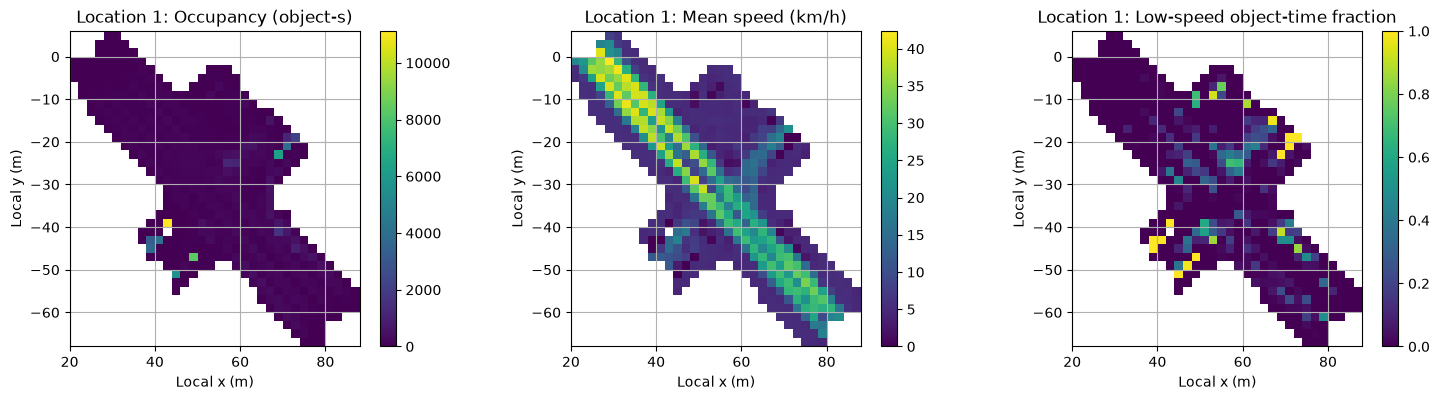

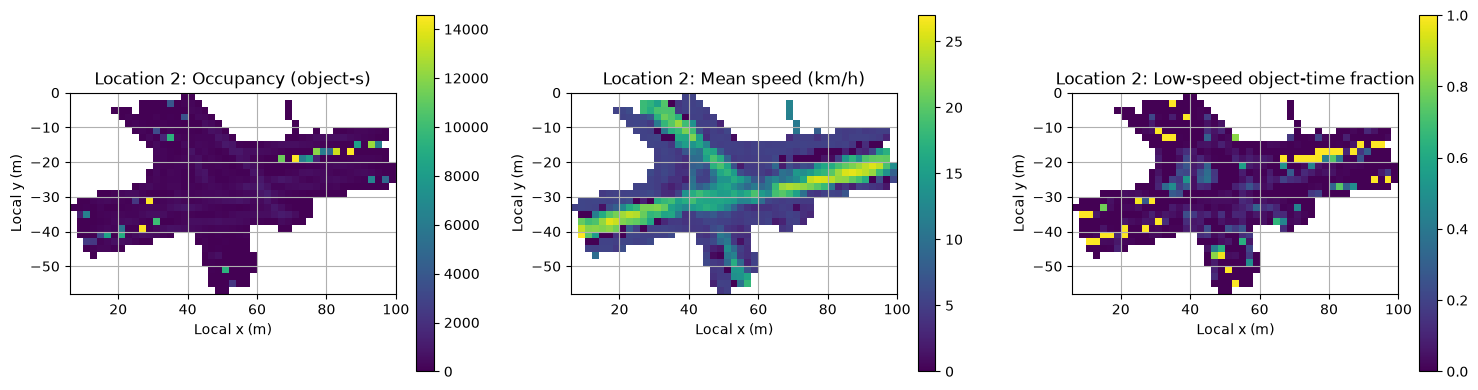

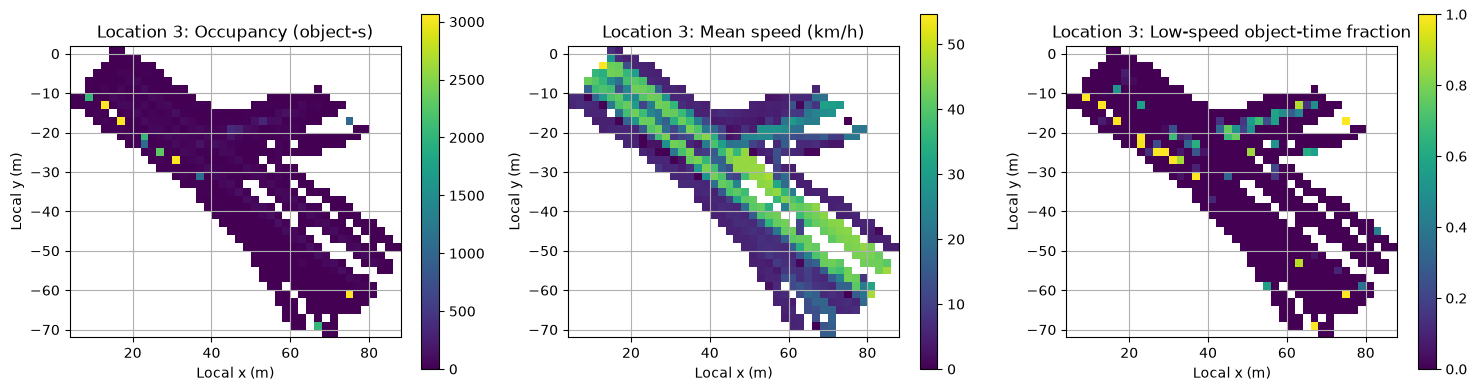

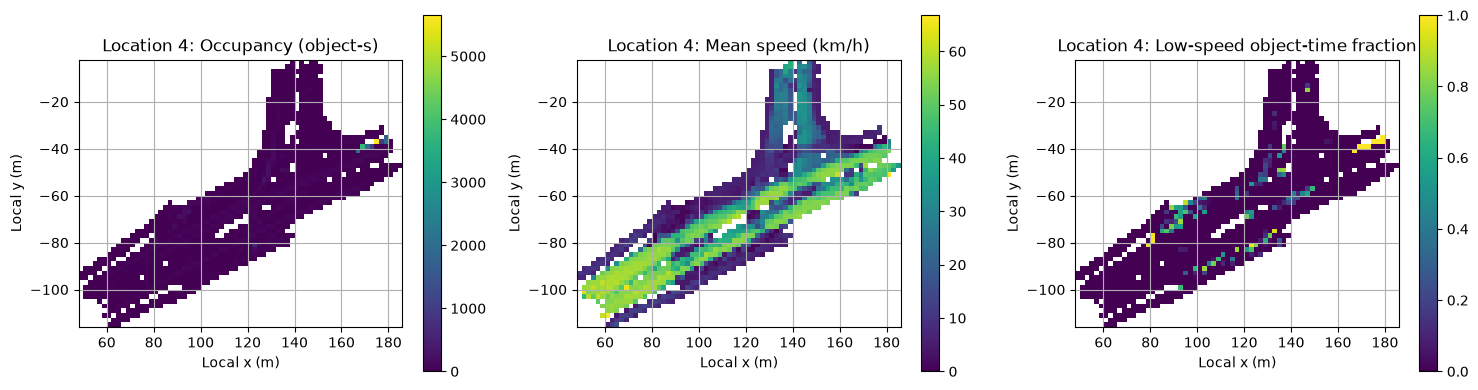

In [149]:
for location, data in read_location_frames():
    xb, yb, panels = spatial_map_data(data)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (values, title, vmax) in zip(axes, panels):
        image = ax.pcolormesh(
            xb, yb, np.ma.masked_invalid(values.T),
            shading='auto', cmap='viridis', vmin=0, vmax=vmax
        )
        ax.set(
            title=f'Location {location}: {title}',
            xlabel='Local x (m)', ylabel='Local y (m)', aspect='equal'
        )
        fig.colorbar(image, ax=ax)

    plt.tight_layout()
    plt.show()


**Interpretation → action:** Bright occupancy can reflect many observations,
long stationary residence or both; it is not a direct count of road users
or traffic flow. The low-speed threshold is a descriptive choice, not proof
that an object is parked.

Recordings are combined within each location, so check coordinate alignment
and scene-layout differences before interpreting spatial patterns. Occupancy
also depends on total recording time, and colour scales can differ between
maps. Do not compare brightness across locations as a measure of traffic
intensity or remove observations based on these plots alone.


### 3.13 Limitations and open questions

#### Zero geometry can reveal a dataset-specific class shortcut
The release sets VRU dimensions to zero [1]. Removing the availability flag leaves those values in the input. This is not automatically direct target leakage, but can limit transfer to a different detector [4]. **Action:** retain data, invent no boxes and later compare classification with/without size features.

#### Observations are already tracked, gap-bridged and smoothed
The upstream pipeline used complete-track context [2]. Removing IDs and velocities does not recreate raw detections. **Action:** describe this as identity reconstruction from processed observations, not a full test of real detector failures; do not smooth again here.

#### Coordinates, orientation and labels need context
Locations have local origins [1]; heading is circular [3]. Upstream class assignment also used size, speed and position [2]. **Action:** avoid arbitrary correlations with integer class IDs and do not treat classification as independent verification of raw image recognition.

#### Limited representation and dependent frames
Selected sites and recording conditions are not all cities, weather or nighttime traffic [2]. Frames of the same object are dependent. **Action:** later report performance by location/recording and class; do not use naive independent-frame uncertainty estimates.

#### Diagnostics are not model results
Distance margins are not confidence, occupancy is not traffic flow, and correlation is not causation. Planned metrics include IDF1/AssA and, with suitable matching, HOTA, plus classwise precision/recall/F1, Macro-F1 and balanced accuracy [5][6]. **Action:** zero-size boxes cannot blindly use IoU; define the later matching protocol and do not fabricate performance plots now.

#### Test-data transparency
All-location descriptive EDA has already occurred. **Action:** disclose it, freeze the evaluation protocol, make model decisions on training/validation and do not change the test location after seeing scores [7].

### 3.14 Understanding → cleaning: decision checkpoint

Before writing cleaning code, record the actual finding, affected units/counts, evidence, intended treatment and reason. A flagged or unusual observation is not automatically an error.

- Separate permanent stationarity candidates from temporary stops; the current parking comparison is not a cleaning decision.
- Interpret zero VRU geometry as a release convention, not a physical zero-size object.
- Review structural problems, missing values and gaps before deleting, imputing or interpolating anything.
- Preserve the imported source and later compare before/after counts for every approved cleaning rule.

**Current status:** no cleaning rules or row-removal policy have been implemented. A future cleaned table must be created separately, not silently substituted for these diagnostic inputs.

## 4. Data cleaning

Identifies and removes unrealistic motor-vehicle tracks. Three independent flags are computed:

| Flag | Criterion |
|---|---|
| `flag_length_implaus` | Bounding-box length outside plausible range |
| `flag_width_implaus` | Bounding-box width outside plausible range |
| `flag_not_traversed` | Track does not enter and exit the intersection zone |

Tracks below `STATIC_PATH_M` are removed immediately (stationary objects, not flagged).
The teleportation check is included for completeness; no spikes were found above `SPEED_SPIKE_RATIO`.

In [247]:
VEHICLE_CLASSES = ["car", "truck_bus"]

# ── Thresholds ───────────────────────────────────────────────────────────────
STATIC_PATH_M      = 2.0
PLAUSIBLE_LENGTH_M = {"car": (2.5, 6.0), "truck_bus": (5.5, 18.75)}
PLAUSIBLE_WIDTH_M  = {"car": (1.5, 2.55), "truck_bus": (2.0,  3.0)}
MIN_PREV_STEP_M    = 0.10
SPEED_SPIKE_RATIO  = 200

# Zone quadrilaterals in inD local metres, CCW — from the zone editor.
ZONES = {
    1: [(61.9372, -54.2109), (78.0232, -41.0382), (49.7778, -10.5129), (34.8318, -24.1923)],
    2: [(33.1852, -45.3446), (72.3234, -37.745),  (63.7105, -16.4659), (26.4722, -24.6989)],
    3: [(14.3127, -20.6457), (65.4837, -56.9974), (85.6228, -34.1984), (37.9983,  -1.0133)],
    4: [(89.272,  -109.1754), (166.1633, -62.9103), (158.3438, -24.4647), (63.6416, -73.3363)],
}
assert len(ZONES) == 4

THRESHOLD_COLOR = "#c0392b"

#### Helper functions

In [248]:
def side_matrix(xy, quad):
    """(n, 4) cross products per point and edge. Inside = all >= 0 for a CCW quad."""
    q = np.asarray(quad, float)
    e = np.roll(q, -1, axis=0) - q
    d = np.asarray(xy, float)[:, None, :] - q
    return e[:, 0] * d[:, :, 1] - e[:, 1] * d[:, :, 0]


def traverses(xy, quad):
    """True if the track starts outside, passes through the zone, and ends outside."""
    inside = (side_matrix(xy, quad) >= 0).all(axis=1)
    return not inside[0] and not inside[-1] and bool(inside.any())

#### Build motor-vehicle track list

In [249]:
# Start from already-imported meta_all; add locationId from inventory.
tracks = (
    meta_all[meta_all["class"].isin(VEHICLE_CLASSES)]
    .merge(inventory[["recordingId", "locationId"]], on="recordingId")
    .reset_index(drop=True)
)

# Compute path length and traversal flag per track.
path_rows = []
for recording_id in RECORDINGS:
    sub = tracks.loc[tracks["recordingId"] == recording_id]
    if sub.empty:
        continue
    valid_ids   = sub["trackId"]
    location_id = int(sub["locationId"].iloc[0])
    quad        = ZONES[location_id]

    df = pd.read_csv(csv_path(recording_id, "tracks"),
                     usecols=["trackId", "frame", "xCenter", "yCenter"])
    df = df[df["trackId"].isin(valid_ids)].sort_values(["trackId", "frame"])
    df["step"] = np.hypot(
        df.groupby("trackId")["xCenter"].diff(),
        df.groupby("trackId")["yCenter"].diff(),
    )

    trav = {
        tid: not traverses(grp[["xCenter", "yCenter"]].values, quad)
        for tid, grp in df.groupby("trackId")
    }

    path = df.groupby("trackId")["step"].sum().rename("path_m").reset_index()
    path["flag_not_traversed"] = path["trackId"].map(trav)
    path.insert(0, "recordingId", recording_id)
    path_rows.append(path)

tracks = tracks.merge(
    pd.concat(path_rows, ignore_index=True),
    on=["recordingId", "trackId"], validate="one_to_one",
)

# Drop static tracks before any further processing.
n_static = (tracks["path_m"] < STATIC_PATH_M).sum()
tracks = tracks[tracks["path_m"] >= STATIC_PATH_M].reset_index(drop=True)
print(f"Static tracks removed : {n_static:,}")
print(f"{len(tracks):,} vehicle tracks  |  "
      f"car: {(tracks['class']=='car').sum():,}  "
      f"truck_bus: {(tracks['class']=='truck_bus').sum():,}")

Static tracks removed : 341
7,892 vehicle tracks  |  car: 7,538  truck_bus: 354


### 4.1 · Bounding Box Dimensions

Plausible length and width ranges were defined per vehicle class. Tracks outside those bounds are flagged for removal.

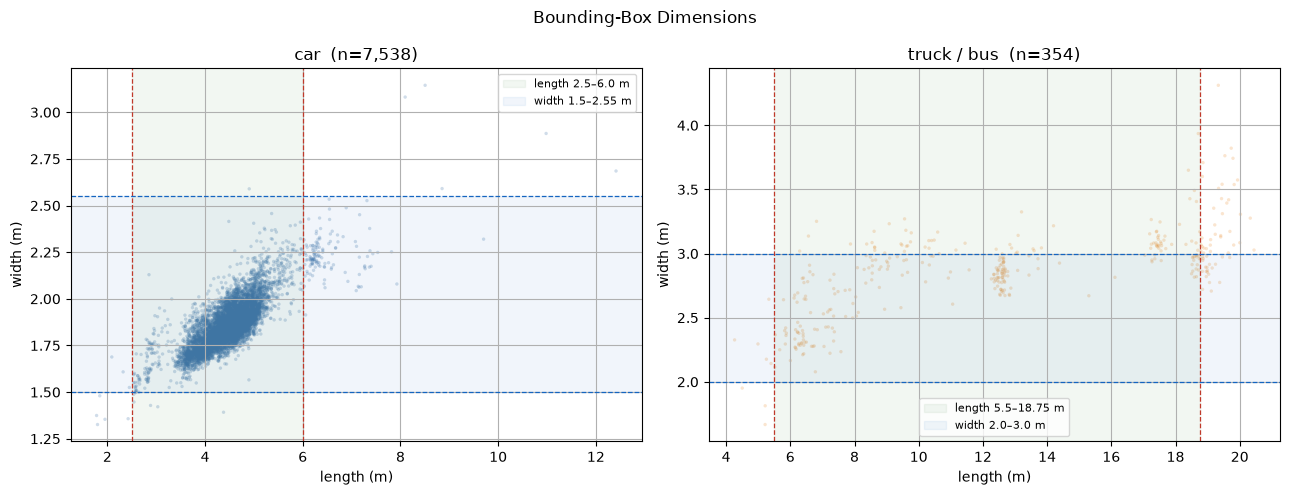

In [250]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cls in zip(axes, VEHICLE_CLASSES):
    subset     = tracks[tracks["class"] == cls]
    lo_l, hi_l = PLAUSIBLE_LENGTH_M[cls]
    lo_w, hi_w = PLAUSIBLE_WIDTH_M[cls]
    ax.scatter(subset["length"], subset["width"],
               s=6, alpha=0.25, color=CLASS_COLORS[cls], edgecolors="none")
    ax.axvspan(lo_l, hi_l, alpha=0.06, color="#2e7d32", label=f"length {lo_l}\u2013{hi_l} m")
    ax.axhspan(lo_w, hi_w, alpha=0.06, color="#1565c0", label=f"width {lo_w}\u2013{hi_w} m")
    for v in [lo_l, hi_l]: ax.axvline(v, color=THRESHOLD_COLOR, ls="--", lw=0.9)
    for v in [lo_w, hi_w]: ax.axhline(v, color="#1565c0",       ls="--", lw=0.9)
    ax.set_title(f"{cls.replace('_', ' / ')}  (n={len(subset):,})")
    ax.set_xlabel("length (m)"); ax.set_ylabel("width (m)"); ax.legend(fontsize=8)
fig.suptitle("Bounding-Box Dimensions"); fig.tight_layout(); plt.show()

In [251]:
tracks["flag_length_implaus"] = ~tracks.apply(
    lambda r: PLAUSIBLE_LENGTH_M[r["class"]][0] <= r["length"] <= PLAUSIBLE_LENGTH_M[r["class"]][1], axis=1)
tracks["flag_width_implaus"]  = ~tracks.apply(
    lambda r: PLAUSIBLE_WIDTH_M[r["class"]][0]  <= r["width"]  <= PLAUSIBLE_WIDTH_M[r["class"]][1],  axis=1)

n_l = tracks["flag_length_implaus"].sum()
n_w = tracks["flag_width_implaus"].sum()
print(f"flag_length_implaus: {n_l:,} ({100 * n_l / len(tracks):.1f}%)")
print(f"flag_width_implaus:  {n_w:,} ({100 * n_w / len(tracks):.1f}%)")

flag_length_implaus: 211 (2.7%)
flag_width_implaus:  135 (1.7%)


### 4.2 · Teleportation

Step ratio per frame: $r = \text{step}_t / \text{step}_{t-1} \times 100$ (100 = constant speed). Frames with $\text{step}_{t-1} \le$ `MIN_PREV_STEP_M` (0.10 m) are skipped to avoid noise-driven spikes at low speed. A track is flagged if any $r >$ `SPEED_SPIKE_RATIO` (200, i.e. twice the previous step).

**Result:** no tracks flagged. The maximum is $r = 135.3$ (35 % apparent speed increase in one frame); a genuine tracker jump would be a multiple of the previous step.

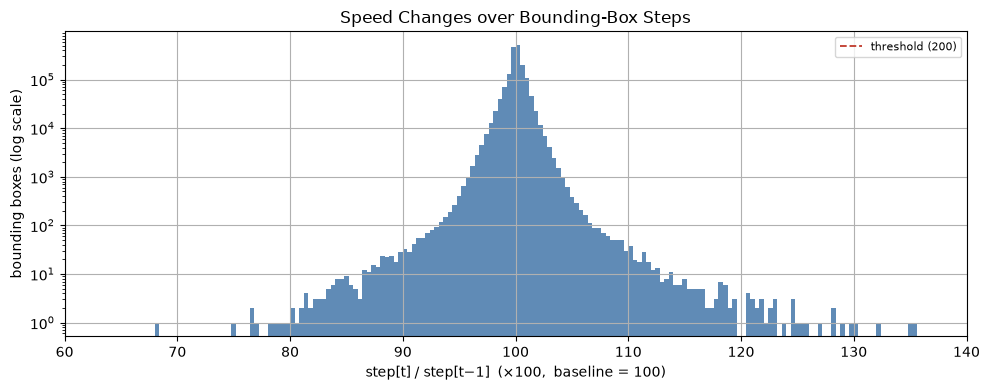

Max r = 135.3; tracks flagged (r > 200): 0


In [252]:
ratio_rows = []

for recording_id in RECORDINGS:
    valid_ids = tracks.loc[tracks["recordingId"] == recording_id, "trackId"]
    if valid_ids.empty:
        continue
    df = pd.read_csv(csv_path(recording_id, "tracks"),
                     usecols=["trackId", "frame", "xCenter", "yCenter"])
    df = df[df["trackId"].isin(valid_ids)].sort_values(["trackId", "frame"])
    df["step"] = np.hypot(
        df.groupby("trackId")["xCenter"].diff(),
        df.groupby("trackId")["yCenter"].diff(),
    )
    df["prev_step"] = df.groupby("trackId")["step"].shift(1)
    mask = df["prev_step"] > MIN_PREV_STEP_M
    df.loc[mask, "ratio_pct"] = df["step"] / df["prev_step"] * 100
    df.insert(0, "recordingId", recording_id)
    ratio_rows.append(
        df[["recordingId", "trackId", "frame", "ratio_pct"]].dropna(subset=["ratio_pct"])
    )

ratios = pd.concat(ratio_rows, ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(ratios["ratio_pct"], bins=200, color=CLASS_COLORS["car"], alpha=0.85, range=(60, 140))
ax.axvline(SPEED_SPIKE_RATIO, color=THRESHOLD_COLOR, linestyle="--", linewidth=1.3,
           label=f"threshold ({SPEED_SPIKE_RATIO})")
ax.set_xlim(60, 140)
ax.set_yscale("log")
ax.set_xlabel("step[t] / step[t\u22121]  (\u00d7100,  baseline = 100)")
ax.set_ylabel("bounding boxes (log scale)")
ax.set_title("Speed Changes over Bounding-Box Steps")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

flagged = ratios.loc[ratios["ratio_pct"] > SPEED_SPIKE_RATIO, ["recordingId", "trackId"]].drop_duplicates()
print(f"Max r = {ratios['ratio_pct'].max():.1f}; tracks flagged (r > {SPEED_SPIKE_RATIO}): {len(flagged)}")

### 4.3 · Zone Traversal

A convex quadrilateral per location defines the intersection area. A track is flagged if it does not start outside, pass through the zone, and end outside.

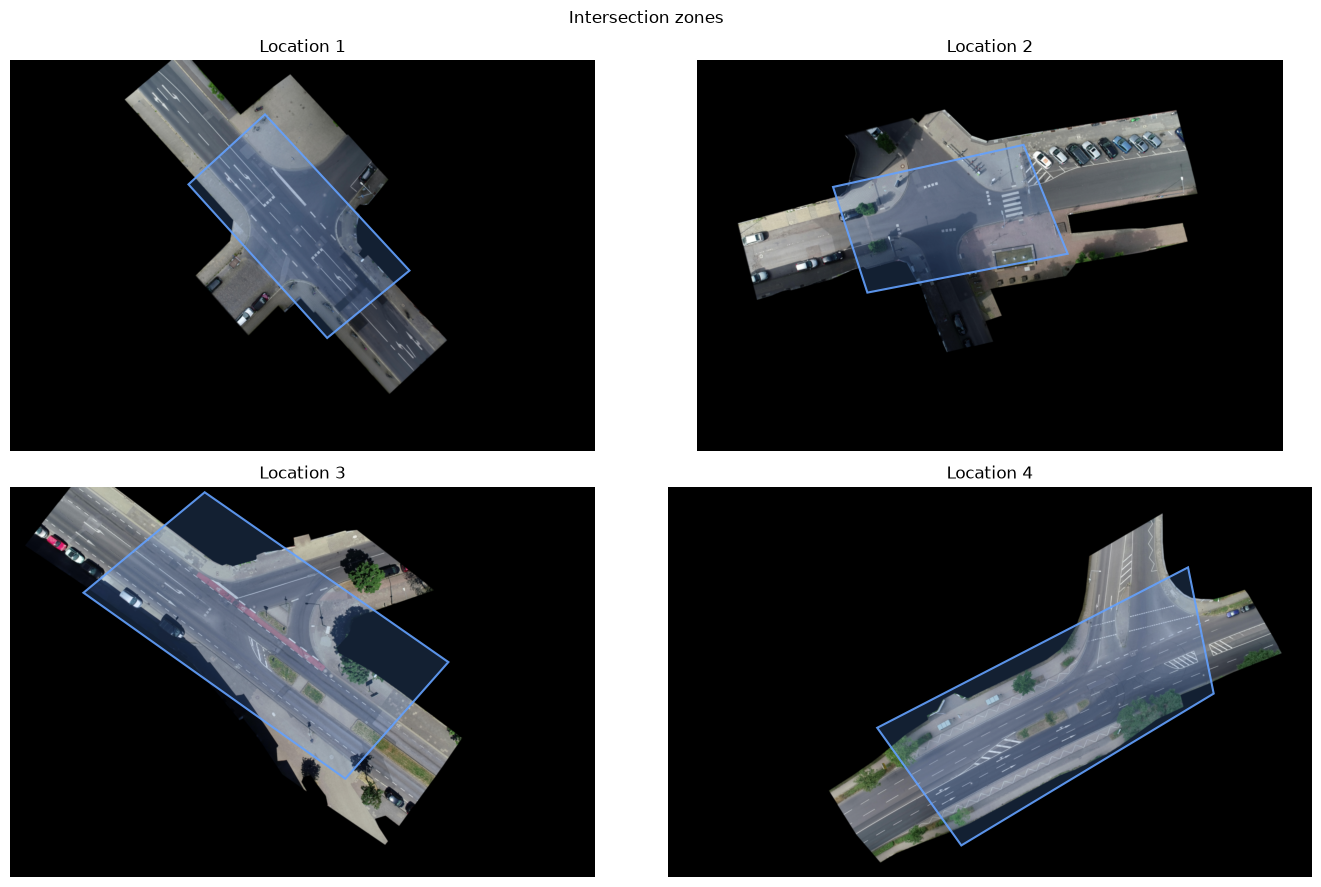

In [253]:
from matplotlib.patches import Polygon as MplPolygon

SCALE_DOWN = 12  # must stay in sync with app.js CONFIG.scaleDown

first_recs = inventory.groupby("locationId")["recordingId"].min()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, loc in zip(axes.flat, sorted(ZONES)):
    rec_id = first_recs[loc]
    _, recording_meta_row = read_metadata(rec_id)
    px_per_m = 1 / (recording_meta_row.orthoPxToMeter * SCALE_DOWN)

    img = plt.imread(DATA_DIR / f"{str(rec_id).zfill(2)}_background.png")
    ax.imshow(img)

    quad_px = [(x * px_per_m, -y * px_per_m) for x, y in ZONES[loc]]
    ax.add_patch(MplPolygon(quad_px, closed=True,
                            facecolor=(0.39, 0.63, 1.0, 0.2),
                            edgecolor=(0.39, 0.63, 1.0, 0.9),
                            linewidth=1.5))
    ax.set_title(f"Location {loc}", pad=6)
    ax.axis("off")

fig.suptitle("Intersection zones")
fig.tight_layout()
plt.show()

In [254]:
n_trav = tracks["flag_not_traversed"].sum()
print(f"flag_not_traversed : {n_trav:,} ({100 * n_trav / len(tracks):.1f}%)")

flag_not_traversed : 410 (5.2%)


### Export

Combine all flags, write the cleaned track list, then assemble a dataframe joined with recording metadata.

In [255]:
FLAG_COLS = ["flag_length_implaus", "flag_width_implaus", "flag_not_traversed"]

tracks_clean = tracks[~tracks[FLAG_COLS].any(axis=1)].drop(columns=FLAG_COLS)

n_removed = len(tracks) - len(tracks_clean)
print(f"Removed : {n_removed:,} of {len(tracks):,} tracks ({100 * n_removed / len(tracks):.1f}%)")
print(f"Kept    : {len(tracks_clean):,}")

tracks_clean.to_csv("tracks_clean.csv", index=False)
print("Written : tracks_clean.csv")

# Join with recording-level metadata from inventory.
training = tracks_clean.merge(inventory, on=["recordingId", "locationId"])

print(f"\nTraining set: {len(training):,} tracks  "
      f"\u00b7 {training['recordingId'].nunique()} recordings  "
      f"\u00b7 {training['locationId'].nunique()} locations")
print(training.groupby(["locationId", "class"]).size().rename("n_tracks")
      .reset_index().to_string(index=False))

Removed : 602 of 7,892 tracks (7.6%)
Kept    : 7,290
Written : tracks_clean.csv

Training set: 7,290 tracks  · 33 recordings  · 4 locations
 locationId     class  n_tracks
          1       car      2292
          1 truck_bus        44
          2       car      2073
          2 truck_bus         2
          3       car      1043
          3 truck_bus        19
          4       car      1740
          4 truck_bus        77


## 5. Further data preparation

*Reserved for later. No train/validation/test split, feature/target construction, scaling or prepared-data export is implemented in this version.*

## 6. Modelling and training

*Reserved for later. No baseline, model or training code.*

## 7. Evaluation and error analysis

*Reserved for later. No model scores or prediction plots.*

## 8. Handoff / deployment

*Reserved for later, depending on the academic project scope.*

## 9. Monitoring

*Optional future phase if a model is deployed; not part of the current work.*

## Appendix — optional helper checks

These tiny, explicitly synthetic examples test code behaviour, not the inD dataset. They are placed outside the main analysis. You may skip them without changing the analysis or exports; they do not substitute for a real CSV/plot run.

In [256]:
# Check elapsed time across a frame gap using a known artificial example.
example = motion_steps(np.array([0, 1, 3]), np.array([0., 1., 5.]), np.zeros(3), 2.)
np.testing.assert_allclose(example['speed_m_s'], [2., 4.])

# Duplicates do not increase temporal coverage.
example = continuity_stats([0, 1, 4, 4])
assert example['missing_frames'] == 2
assert np.isclose(example['coverage'], 3 / 5)

# A closer wrong candidate produces a negative distance margin.
example = association_distances(np.array([[0., 0.]]), [1], np.array([[2., 0.], [.5, 0.]]), [1, 2])
assert example[0]['margin_m'] < 0

# Opposing directions should not produce a meaningful circular mean.
example = circular_summary(np.array([0., 90., 180., 270.]))
assert np.isnan(example['circular_mean_deg'])
print('Optional synthetic checks passed; these are not dataset results.')

Optional synthetic checks passed; these are not dataset results.


## Appendix — sources, execution status and next steps

### Sources
- [1] [Official inD format](https://levelxdata.com/wp-content/uploads/2023/10/inD-Format.pdf): geometry conventions, tables and coordinates.
- [2] [Bock et al., The inD Dataset](https://ar5iv.labs.arxiv.org/html/1911.07602), Section IV A–E: data creation.
- [3] [SciPy circular mean](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.circmean.html).
- [4] [Geirhos et al., Shortcut learning](https://www.nature.com/articles/s42256-020-00257-z), 2020.
- [5] [HOTA](https://arxiv.org/pdf/2009.07736v1) and [identity metrics](https://users.cs.duke.edu/~tomasi/papers/ristani/ristaniBmtt16.pdf).
- [6] [Macro-F1](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.f1_score.html) and [balanced accuracy](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.balanced_accuracy_score.html).
- [7] [scikit-learn: avoiding leakage](https://scikit-learn.org/stable/common_pitfalls.html).
- Further reading: [better figures](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1003833), [ECDFs](https://seaborn.pydata.org/tutorial/distributions.html), [structured cross-validation](https://nsojournals.onlinelibrary.wiley.com/doi/abs/10.1111/ecog.02881).
- Course reference: the supplied `DIS_Lecture_3_DataUnderstanding_DataPreparation.pdf`.

Source retrieval: 30 October 2026. Sampling choices and diagnostics are our project decisions, not claims made by those sources.

### Dependencies and verification
Use Python ≥ 3.10, `numpy>=1.26`, `pandas>=2.2`, `matplotlib>=3.9` and `jupyterlab>=4` (including IPython). If needed, install these locally in the notebook environment: `python -m pip install "numpy>=1.26" "pandas>=2.2" "matplotlib>=3.9" "jupyterlab>=4"`.

The delivered notebook is not pre-executed. JSON and code syntax plus isolated numerical helper tests are checked during creation. A full CSV run and visual chart verification were not performed: pandas/matplotlib are unavailable in the creation environment, and the previously blocked dataset runtime was not repeated or bypassed. Synthetic checks in the appendix are clearly labelled tests, not EDA results.

### Next steps — two sentences
First, run and review the data-understanding section on recordings `00`–`32`, record the actual findings and agree on justified cleaning rules without automatically discarding temporary stops. Then implement and validate those rules in Section 4 with before/after counts; keep further preparation, modelling and evaluation empty until the cleaning decisions have been reviewed.